# Joint Improved LSTM + GNN Occupancy Prediction — All 5 Rooms

## Final notebook

This notebook implements **one joint spatio-temporal LSTM + GNN model for all five rooms**.

It is designed around the project's room-level occupant-count forecasting task.

### Input
`(batch, historical time steps, 5 rooms, features)`

### Output
`(batch, 5 rooms)`

### Architecture

```text
                 ALL 5 ROOMS
                     │
                     ▼
       Historical environmental + occupancy data
                     │
                     ▼
        Graph Convolution at EVERY time step
                     │
                     ▼
          Spatial residual graph block
                     │
                     ▼
           Shared LSTM for all rooms
                     │
                     ▼
       Temporal residual / normalization
                     │
                     ▼
        Second graph-convolution block
                     │
                     ▼
          Shared prediction head
                     │
                     ▼
          [R1, R2, R3, R4, R5]
```

The model is joint: all five rooms are present in the same tensor, the GNN mixes information between rooms, the LSTM parameters are shared across rooms, and the model is trained against all five room targets simultaneously.

No independent room-specific LSTM models are used.

## 1. Install dependencies

In [5]:
%pip -q install pandas numpy scikit-learn matplotlib tensorflow joblib

## 2. Imports and reproducibility

In [6]:
import os
import glob
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras import layers, Model

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


## 3. Configuration

In [7]:
# ============================================================
# ROOMS
# ============================================================

ROOMS = [
    "Room 1",
    "Room 2",
    "Room 3",
    "Room 4",
    "Room 5",
]

N_ROOMS = len(ROOMS)

TIMESTAMP_COL = "timestamp"
TARGET_COL = "occupant_count"

# ------------------------------------------------------------
# TIME SERIES
# ------------------------------------------------------------

# 12 x 5 minutes = 60-minute lookback
SEQ_LEN = 12

# 3 x 5 minutes = 15-minute forecast horizon
HORIZON = 3

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15

# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

GNN_HIDDEN = 96
LSTM_UNITS = 128

DROPOUT = 0.20

LEARNING_RATE = 3e-4
BATCH_SIZE = 64
EPOCHS = 100

# ------------------------------------------------------------
# GRAPH
# ------------------------------------------------------------

# Fully connected cross-room graph.
#
# IMPORTANT:
# This is an experimental topology because a verified
# physical room adjacency matrix is not available here.
#
# Each room communicates with all other rooms.
#
ADJACENCY = np.array([
    [0, 1, 1, 1, 1],
    [1, 0, 1, 1, 1],
    [1, 1, 0, 1, 1],
    [1, 1, 1, 0, 1],
    [1, 1, 1, 1, 0],
], dtype=np.float32)

assert ADJACENCY.shape == (5, 5)

OUTPUT_DIR = "/content/joint_lstm_gnn_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Rooms:", ROOMS)
print("Sequence length:", SEQ_LEN)
print("History duration:", SEQ_LEN * 5, "minutes")
print("Forecast horizon:", HORIZON * 5, "minutes")
print("GNN hidden:", GNN_HIDDEN)
print("LSTM units:", LSTM_UNITS)

Rooms: ['Room 1', 'Room 2', 'Room 3', 'Room 4', 'Room 5']
Sequence length: 12
History duration: 60 minutes
Forecast horizon: 15 minutes
GNN hidden: 96
LSTM units: 128


## 4. Locate the five datasets

Upload these files to Colab:

`combined_Room1.csv` through `combined_Room5.csv`

The notebook searches `/content` and the current directory.

In [8]:
import glob
import os

KAGGLE_DIR = "/kaggle/input/datasets/fishonk/pjt1h1"


def find_room_file(room_number):
    filename = f"combined_Room{room_number}.csv"

    # 1. Direct path candidates
    candidates = [
        os.path.join(KAGGLE_DIR, filename),
        filename,
        f"./{filename}",
    ]

    for path in candidates:
        if os.path.exists(path):
            return path

    # 2. Recursive search within the Kaggle dataset folder
    matches = glob.glob(
        os.path.join(KAGGLE_DIR, "**", filename), recursive=True
    )

    if matches:
        return matches[0]

    # 3. General workspace recursive search fallback
    matches = glob.glob(f"**/{filename}", recursive=True)

    return matches[0] if matches else None


DATA_FILES = {room: find_room_file(i + 1) for i, room in enumerate(ROOMS)}

missing = [room for room, path in DATA_FILES.items() if path is None]

if missing:
    print("Missing files:")
    for room in missing:
        print(" -", room)

    raise FileNotFoundError(
        f"Could not find room CSVs in '{KAGGLE_DIR}'. Please check your Kaggle dataset inputs."
    )

for room, path in DATA_FILES.items():
    print(room, "->", path)

Room 1 -> combined_Room1.csv
Room 2 -> combined_Room2.csv
Room 3 -> combined_Room3.csv
Room 4 -> combined_Room4.csv
Room 5 -> combined_Room5.csv


## 5. Column matching

The source files can use names such as:

- `illuminance [lux]`
- `sound_pressure_level [dba]`
- `air_temperature [Celsius]`
- `indoor_relative_humidity [%]`
- `indoor_co2 [ppm]`

The loader maps these to consistent internal names.

In [9]:
SENSOR_ALIASES = {
    "illuminance": [
        "illuminance",
        "illuminance [lux]",
    ],

    "sound_pressure_level": [
        "sound_pressure_level",
        "sound_pressure_level [dba]",
    ],

    "indoor_temperature": [
        "indoor_temperature",
        "air_temperature",
        "air_temperature [celsius]",
        "indoor air temperature",
    ],

    "dry_bulb_temperature": [
        "dry_bulb_temp",
        "dry_bulb_temp [celsius]",
        "dry bulb temperature",
    ],

    "indoor_relative_humidity": [
        "indoor_relative_humidity",
        "indoor_relative_humidity [%]",
    ],

    "outdoor_relative_humidity": [
        "outdoor_relative_humidity",
        "outdoor_relative_humidity [%]",
    ],

    "indoor_co2": [
        "indoor_co2",
        "indoor_co2 [ppm]",
    ],
}

TARGET_ALIASES = [
    "occupant_count",
    "occupant_count [number]",
    "occupant count",
    "occupancy_count",
]


def normalize_name(name):
    return " ".join(
        str(name)
        .strip()
        .lower()
        .replace("_", " ")
        .split()
    )


def find_column(df, aliases, required=True):
    normalized = {
        normalize_name(c): c
        for c in df.columns
    }

    # Exact normalized match
    for alias in aliases:
        key = normalize_name(alias)
        if key in normalized:
            return normalized[key]

    # Substring fallback
    for alias in aliases:
        key = normalize_name(alias)

        for normalized_col, original_col in normalized.items():
            if key in normalized_col or normalized_col in key:
                return original_col

    if required:
        raise KeyError(
            f"Could not find any of: {aliases}"
        )

    return None

## 6. Load and clean each room

In [10]:
def load_room(room, path):
    df = pd.read_csv(path).copy()

    rename_map = {}

    # Timestamp
    timestamp_source = find_column(
        df,
        [TIMESTAMP_COL],
        required=True,
    )

    if timestamp_source != TIMESTAMP_COL:
        rename_map[timestamp_source] = TIMESTAMP_COL

    # Target
    target_source = find_column(
        df,
        TARGET_ALIASES,
        required=True,
    )

    rename_map[target_source] = TARGET_COL

    # Sensors
    for standard_name, aliases in SENSOR_ALIASES.items():
        source = find_column(
            df,
            aliases,
            required=False,
        )

        if source is not None:
            rename_map[source] = standard_name

    df = df.rename(columns=rename_map)

    # Timestamp
    df[TIMESTAMP_COL] = pd.to_datetime(
        df[TIMESTAMP_COL],
        errors="coerce",
        utc=True,
    )

    df = (
        df.dropna(subset=[TIMESTAMP_COL])
          .sort_values(TIMESTAMP_COL)
          .drop_duplicates(
              subset=[TIMESTAMP_COL],
              keep="first",
          )
          .copy()
    )

    # Numeric columns
    numeric_columns = [
        TARGET_COL
    ] + [
        c
        for c in SENSOR_ALIASES
        if c in df.columns
    ]

    for col in numeric_columns:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce",
        )

    sensor_columns = [
        c
        for c in SENSOR_ALIASES
        if c in df.columns
    ]

    if not sensor_columns:
        raise ValueError(
            f"{room}: no usable environmental sensor columns found."
        )

    # Interpolate sensor data only.
    # Never fabricate the occupancy target.
    df = df.set_index(TIMESTAMP_COL)

    df[sensor_columns] = (
        df[sensor_columns]
        .interpolate(
            method="time",
            limit_direction="both",
        )
        .ffill()
        .bfill()
    )

    df = (
        df.dropna(subset=[TARGET_COL])
          .reset_index()
    )

    return df


room_dfs = {}

for room, path in DATA_FILES.items():

    room_dfs[room] = load_room(
        room,
        path,
    )

    df = room_dfs[room]

    print(
        f"{room}: "
        f"{len(df):,} rows | "
        f"{len(df.columns)} columns | "
        f"{df[TIMESTAMP_COL].min()} -> "
        f"{df[TIMESTAMP_COL].max()}"
    )

Room 1: 8,352 rows | 27 columns | 2021-09-06 16:00:00+00:00 -> 2021-12-23 15:55:00+00:00
Room 2: 8,352 rows | 27 columns | 2021-09-06 16:00:00+00:00 -> 2021-12-23 15:55:00+00:00
Room 3: 8,352 rows | 35 columns | 2021-09-06 16:00:00+00:00 -> 2021-12-23 15:55:00+00:00
Room 4: 13,536 rows | 35 columns | 2021-09-06 16:00:00+00:00 -> 2021-12-23 15:55:00+00:00
Room 5: 13,536 rows | 35 columns | 2021-09-06 16:00:00+00:00 -> 2021-12-23 15:55:00+00:00


## 7. Time feature engineering

Cyclical features are added so the model can distinguish periodic time patterns without treating midnight as far away from 23:59.

Historical occupancy is later included as an input feature.

In [11]:
def add_time_features(df):
    df = df.copy()

    minutes = (
        df[TIMESTAMP_COL].dt.hour * 60
        + df[TIMESTAMP_COL].dt.minute
    )

    dow = df[TIMESTAMP_COL].dt.dayofweek

    df["sin_hour"] = np.sin(
        2 * np.pi * minutes / (24 * 60)
    )

    df["cos_hour"] = np.cos(
        2 * np.pi * minutes / (24 * 60)
    )

    df["sin_week"] = np.sin(
        2 * np.pi * dow / 7
    )

    df["cos_week"] = np.cos(
        2 * np.pi * dow / 7
    )

    df["is_weekend"] = (
        dow >= 5
    ).astype(np.float32)

    return df


for room in ROOMS:
    room_dfs[room] = add_time_features(
        room_dfs[room]
    )


candidate_sensors = [
    "illuminance",
    "sound_pressure_level",
    "indoor_temperature",
    "dry_bulb_temperature",
    "indoor_relative_humidity",
    "outdoor_relative_humidity",
    "indoor_co2",
]

COMMON_SENSOR_FEATURES = [
    feature
    for feature in candidate_sensors
    if all(
        feature in room_dfs[room].columns
        for room in ROOMS
    )
]

TIME_FEATURES = [
    "sin_hour",
    "cos_hour",
    "sin_week",
    "cos_week",
    "is_weekend",
]

INPUT_FEATURES = (
    COMMON_SENSOR_FEATURES
    + TIME_FEATURES
    + [TARGET_COL]
)

print("Common sensors:")
print(COMMON_SENSOR_FEATURES)

print("\nTime features:")
print(TIME_FEATURES)

print("\nHistorical occupancy included:")
print(TARGET_COL in INPUT_FEATURES)

print("\nTotal features per room:")
print(len(INPUT_FEATURES))

Common sensors:
['illuminance', 'sound_pressure_level', 'indoor_temperature', 'dry_bulb_temperature', 'indoor_relative_humidity', 'outdoor_relative_humidity', 'indoor_co2']

Time features:
['sin_hour', 'cos_hour', 'sin_week', 'cos_week', 'is_weekend']

Historical occupancy included:
True

Total features per room:
13


## 8. Synchronize all five rooms

This is critical for the GNN.

At each timestamp, the five room nodes must represent the same moment in time.

Only timestamps shared by all five rooms are retained.

In [12]:
indexed = {}

for room in ROOMS:

    selected = room_dfs[room][
        [TIMESTAMP_COL] + INPUT_FEATURES
    ].copy()

    selected = (
        selected
        .set_index(TIMESTAMP_COL)
        .sort_index()
        .drop_duplicates()
    )

    indexed[room] = selected


common_index = indexed[ROOMS[0]].index

for room in ROOMS[1:]:
    common_index = common_index.intersection(
        indexed[room].index
    )

common_index = common_index.sort_values()

print(
    "Common synchronized timestamps:",
    len(common_index)
)

if len(common_index) < (
    SEQ_LEN + HORIZON + 100
):
    raise ValueError(
        "Too few synchronized timestamps."
    )


X_room = []
Y_room = []

for room in ROOMS:

    aligned = indexed[room].reindex(
        common_index
    )

    if aligned[INPUT_FEATURES].isna().any().any():
        missing_rows = int(
            aligned[INPUT_FEATURES]
            .isna()
            .any(axis=1)
            .sum()
        )

        raise ValueError(
            f"{room}: {missing_rows} synchronized "
            "rows have missing inputs."
        )

    X_room.append(
        aligned[INPUT_FEATURES]
        .to_numpy(dtype=np.float32)
    )

    Y_room.append(
        aligned[TARGET_COL]
        .to_numpy(dtype=np.float32)
    )


# [time, rooms, features]
X_all = np.stack(
    X_room,
    axis=1,
)

# [time, rooms]
Y_all = np.stack(
    Y_room,
    axis=1,
)


print("X_all shape:", X_all.shape)
print("Y_all shape:", Y_all.shape)

assert X_all.shape[1] == N_ROOMS
assert Y_all.shape[1] == N_ROOMS

Common synchronized timestamps: 8352
X_all shape: (8352, 5, 13)
Y_all shape: (8352, 5)


## 9. Check timestamp intervals

In [13]:
for room in ROOMS:

    idx = indexed[room].index

    diffs = (
        idx.to_series()
        .diff()
        .dropna()
        .dt.total_seconds()
        / 60
    )

    print(
        f"{room}: "
        f"median interval = "
        f"{diffs.median():.2f} minutes"
    )


common_diffs = (
    common_index
    .to_series()
    .diff()
    .dropna()
    .dt.total_seconds()
    / 60
)

print(
    "\nSynchronized median interval:",
    common_diffs.median(),
    "minutes"
)

print(
    "Timeline:",
    common_index.min(),
    "->",
    common_index.max()
)

Room 1: median interval = 5.00 minutes
Room 2: median interval = 5.00 minutes
Room 3: median interval = 5.00 minutes
Room 4: median interval = 5.00 minutes
Room 5: median interval = 5.00 minutes

Synchronized median interval: 5.0 minutes
Timeline: 2021-09-06 16:00:00+00:00 -> 2021-12-23 15:55:00+00:00


## 10. Chronological train / validation / test split

The split happens on the common timeline before sequence construction.

No random train/test split is used.

In [14]:
n = len(common_index)

train_end = int(
    n * TRAIN_RATIO
)

val_end = int(
    n * (TRAIN_RATIO + VAL_RATIO)
)

print("Train:", train_end)
print(
    "Validation:",
    val_end - train_end
)
print("Test:", n - val_end)

print("\nTRAIN")
print(
    common_index[0],
    "->",
    common_index[train_end - 1]
)

print("\nVALIDATION")
print(
    common_index[train_end],
    "->",
    common_index[val_end - 1]
)

print("\nTEST")
print(
    common_index[val_end],
    "->",
    common_index[-1]
)

Train: 5846
Validation: 1253
Test: 1253

TRAIN
2021-09-06 16:00:00+00:00 -> 2021-12-12 23:05:00+00:00

VALIDATION
2021-12-12 23:10:00+00:00 -> 2021-12-17 07:30:00+00:00

TEST
2021-12-17 07:35:00+00:00 -> 2021-12-23 15:55:00+00:00


## 11. Scale using training data only

Each room receives separate sensor and target scalers.

This is important because Room 2, for example, can have a very different occupancy range from Room 1.

The occupancy target is also used as **historical occupancy input**, using only past values.

In [15]:
n_sensor_features = len(INPUT_FEATURES) - 1

X_scaled = np.zeros_like(
    X_all,
    dtype=np.float32,
)

Y_scaled = np.zeros_like(
    Y_all,
    dtype=np.float32,
)

sensor_scalers = {}
target_scalers = {}

for node, room in enumerate(ROOMS):

    # Environmental features
    sensor_scaler = StandardScaler()

    sensor_scaler.fit(
        X_all[
            :train_end,
            node,
            :n_sensor_features
        ]
    )

    X_scaled[
        :,
        node,
        :n_sensor_features
    ] = sensor_scaler.transform(
        X_all[
            :,
            node,
            :n_sensor_features
        ]
    ).astype(np.float32)

    # Occupancy target
    target_scaler = StandardScaler()

    target_scaler.fit(
        Y_all[
            :train_end,
            node
        ].reshape(-1, 1)
    )

    # Historical occupancy input
    X_scaled[
        :,
        node,
        -1
    ] = target_scaler.transform(
        Y_all[
            :,
            node
        ].reshape(-1, 1)
    ).reshape(-1).astype(np.float32)

    # Forecast target
    Y_scaled[
        :,
        node
    ] = target_scaler.transform(
        Y_all[
            :,
            node
        ].reshape(-1, 1)
    ).reshape(-1).astype(np.float32)

    sensor_scalers[room] = sensor_scaler
    target_scalers[room] = target_scaler


print("Scaled X:", X_scaled.shape)
print("Scaled Y:", Y_scaled.shape)

Scaled X: (8352, 5, 13)
Scaled Y: (8352, 5)


## 12. Build synchronized multi-room sequences

Each training sample contains all 5 rooms over the historical window.

For a 60-minute history and a 15-minute horizon:

```text
Input  = 12 historical synchronized timestamps × 5 rooms
Target = occupancy vector at t + 15 minutes
```

In [16]:
def make_sequences(
    X,
    Y,
    start,
    end,
    seq_len,
    horizon,
):
    Xs = []
    Ys = []
    positions = []

    first_t = max(
        start + seq_len,
        seq_len
    )

    last_t = (
        end - horizon + 1
    )

    for t in range(
        first_t,
        last_t,
    ):

        target_t = (
            t + horizon - 1
        )

        Xs.append(
            X[
                t - seq_len:t
            ]
        )

        Ys.append(
            Y[target_t]
        )

        positions.append(
            target_t
        )

    return (
        np.asarray(
            Xs,
            dtype=np.float32,
        ),
        np.asarray(
            Ys,
            dtype=np.float32,
        ),
        np.asarray(
            positions,
            dtype=np.int64,
        ),
    )


X_train, Y_train, train_positions = make_sequences(
    X_scaled,
    Y_scaled,
    0,
    train_end,
    SEQ_LEN,
    HORIZON,
)

# Include sequence context before validation boundary,
# but validation targets themselves remain after train_end.
X_val, Y_val, val_positions = make_sequences(
    X_scaled,
    Y_scaled,
    train_end - SEQ_LEN,
    val_end,
    SEQ_LEN,
    HORIZON,
)

# Same logic for test.
X_test, Y_test, test_positions = make_sequences(
    X_scaled,
    Y_scaled,
    val_end - SEQ_LEN,
    n,
    SEQ_LEN,
    HORIZON,
)


print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)

print("X_val  :", X_val.shape)
print("Y_val  :", Y_val.shape)

print("X_test :", X_test.shape)
print("Y_test :", Y_test.shape)

assert X_train.ndim == 4
assert X_train.shape[2] == 5
assert Y_train.shape[1] == 5

X_train: (5832, 12, 5, 13)
Y_train: (5832, 5)
X_val  : (1251, 12, 5, 13)
Y_val  : (1251, 5)
X_test : (1251, 12, 5, 13)
Y_test : (1251, 5)


## 13. Normalize adjacency matrix

In [17]:
def normalize_adjacency(A):

    A = np.asarray(
        A,
        dtype=np.float32,
    )

    # Add self-loops
    A_hat = (
        A
        + np.eye(
            A.shape[0],
            dtype=np.float32,
        )
    )

    degree = A_hat.sum(
        axis=1
    )

    d_inv_sqrt = (
        1.0
        / np.sqrt(
            np.maximum(
                degree,
                1e-8,
            )
        )
    )

    normalized = (
        d_inv_sqrt[:, None]
        * A_hat
        * d_inv_sqrt[None, :]
    )

    return normalized.astype(
        np.float32
    )


A_NORM = normalize_adjacency(
    ADJACENCY
)

print(
    np.round(
        A_NORM,
        3
    )
)

[[0.2 0.2 0.2 0.2 0.2]
 [0.2 0.2 0.2 0.2 0.2]
 [0.2 0.2 0.2 0.2 0.2]
 [0.2 0.2 0.2 0.2 0.2]
 [0.2 0.2 0.2 0.2 0.2]]


## 14. Keras-3-compatible Graph Convolution layer

This custom layer:

- supports graph message passing across the five rooms;
- has explicit `compute_output_shape`;
- is registered for Keras serialization;
- contains no `Lambda` layer.

In [18]:
@tf.keras.utils.register_keras_serializable(
    package="OccupancySTGNN"
)
class GraphConv(layers.Layer):

    def __init__(
        self,
        units,
        adjacency,
        activation="relu",
        **kwargs,
    ):
        super().__init__(
            **kwargs
        )

        self.units = int(units)

        self.activation_name = (
            activation
        )

        self.adjacency = np.asarray(
            adjacency,
            dtype=np.float32,
        )

        self.normalized_adjacency = (
            normalize_adjacency(
                self.adjacency
            )
        )

        self.activation = (
            tf.keras.activations.get(
                activation
            )
        )

    def build(self, input_shape):

        input_dim = int(
            input_shape[-1]
        )

        self.self_kernel = (
            self.add_weight(
                name="self_kernel",
                shape=(
                    input_dim,
                    self.units,
                ),
                initializer="glorot_uniform",
                trainable=True,
            )
        )

        self.neighbor_kernel = (
            self.add_weight(
                name="neighbor_kernel",
                shape=(
                    input_dim,
                    self.units,
                ),
                initializer="glorot_uniform",
                trainable=True,
            )
        )

        self.bias = (
            self.add_weight(
                name="bias",
                shape=(self.units,),
                initializer="zeros",
                trainable=True,
            )
        )

        self.adj_tensor = (
            self.add_weight(
                name="normalized_adjacency",
                shape=self.normalized_adjacency.shape,
                initializer=tf.keras.initializers.Constant(
                    self.normalized_adjacency
                ),
                trainable=False,
            )
        )

        super().build(
            input_shape
        )

    def call(self, inputs):

        # inputs:
        # [batch, nodes, features]

        self_part = tf.matmul(
            inputs,
            self.self_kernel,
        )

        neighbor_features = (
            tf.einsum(
                "ij,bjf->bif",
                self.adj_tensor,
                inputs,
            )
        )

        neighbor_part = (
            tf.matmul(
                neighbor_features,
                self.neighbor_kernel,
            )
        )

        output = (
            self_part
            + neighbor_part
            + self.bias
        )

        if self.activation is not None:
            output = self.activation(
                output
            )

        return output

    def compute_output_shape(
        self,
        input_shape,
    ):
        return (
            tuple(input_shape[:-1])
            + (self.units,)
        )

    def get_config(self):

        config = super().get_config()

        config.update({
            "units": self.units,
            "adjacency": self.adjacency.tolist(),
            "activation": self.activation_name,
        })

        return config

## 15. Build the improved joint LSTM + GNN

This is the main model.

### Spatial block 1
Graph convolution is applied to every historical timestamp.

### Temporal block
A single shared two-layer LSTM is applied to the five room sequences.

### Spatial block 2
Another GNN layer exchanges information after temporal learning.

### Residual fusion
Residual paths make it easier for useful information to flow through the deeper network.

### Output
One shared prediction neuron produces one occupancy-count prediction for each of the five rooms.

In [19]:
def build_improved_joint_stgnn(
    seq_len,
    n_nodes,
    n_features,
    gnn_hidden=96,
    lstm_units=128,
    dropout=0.20,
):

    inputs = layers.Input(
        shape=(
            seq_len,
            n_nodes,
            n_features,
        ),
        name="all_rooms_history",
    )

    # ========================================================
    # SPATIAL BLOCK 1
    # Graph message passing at every timestep
    #
    # [B,T,N,F] -> [B,T,N,H]
    # ========================================================

    x = layers.TimeDistributed(
        GraphConv(
            gnn_hidden,
            ADJACENCY,
            activation="relu",
            name="graph_conv_t1",
        ),
        name="graph_over_history_1",
    )(inputs)

    x = layers.LayerNormalization(
        axis=-1,
        name="spatial_norm_1",
    )(x)

    x = layers.Dropout(
        dropout,
        name="spatial_dropout_1",
    )(x)

    # ========================================================
    # SPATIAL BLOCK 2
    # ========================================================

    x2 = layers.TimeDistributed(
        GraphConv(
            gnn_hidden,
            ADJACENCY,
            activation="relu",
            name="graph_conv_t2",
        ),
        name="graph_over_history_2",
    )(x)

    x2 = layers.LayerNormalization(
        axis=-1,
        name="spatial_norm_2",
    )(x2)

    # Spatial residual connection
    x = layers.Add(
        name="spatial_residual",
    )([
        x,
        x2,
    ])

    x = layers.Activation(
        "relu",
        name="spatial_activation",
    )(x)

    x = layers.Dropout(
        dropout,
        name="spatial_dropout_2",
    )(x)

    # ========================================================
    # TEMPORAL PREPARATION
    #
    # [B,T,N,H] -> [B,N,T,H]
    # ========================================================

    x = layers.Permute(
        (2, 1, 3),
        name="rooms_first",
    )(x)

    # ========================================================
    # SHARED LSTM #1
    #
    # TimeDistributed uses the SAME LSTM parameters for all
    # room nodes.
    # ========================================================

    x = layers.TimeDistributed(
        layers.LSTM(
            lstm_units,
            return_sequences=True,
            dropout=0.10,
            recurrent_dropout=0.0,
            name="shared_lstm_1",
        ),
        name="shared_temporal_lstm_1",
    )(x)

    x = layers.LayerNormalization(
        axis=-1,
        name="temporal_norm_1",
    )(x)

    # ========================================================
    # SHARED LSTM #2
    # ========================================================

    x = layers.TimeDistributed(
        layers.LSTM(
            lstm_units,
            return_sequences=False,
            dropout=0.10,
            recurrent_dropout=0.0,
            name="shared_lstm_2",
        ),
        name="shared_temporal_lstm_2",
    )(x)

    # [B,N,LSTM]
    x = layers.LayerNormalization(
        axis=-1,
        name="temporal_norm_2",
    )(x)

    x = layers.Dropout(
        dropout,
        name="temporal_dropout",
    )(x)

    # ========================================================
    # SPATIAL BLOCK 3
    # Graph reasoning AFTER temporal encoding
    #
    # [B,N,LSTM] -> [B,N,GNN]
    # ========================================================

    x_graph = GraphConv(
        gnn_hidden,
        ADJACENCY,
        activation="relu",
        name="final_graph_conv",
    )(x)

    x_graph = layers.LayerNormalization(
        axis=-1,
        name="final_graph_norm",
    )(x_graph)

    x_graph = layers.Dropout(
        dropout,
        name="final_graph_dropout",
    )(x_graph)

    # ========================================================
    # RESIDUAL TEMPORAL-SPATIAL FUSION
    # ========================================================

    x_residual = layers.Dense(
        gnn_hidden,
        activation=None,
        name="temporal_projection",
    )(x)

    x = layers.Add(
        name="spatiotemporal_residual",
    )([
        x_residual,
        x_graph,
    ])

    x = layers.Activation(
        "relu",
        name="fusion_activation",
    )(x)

    x = layers.LayerNormalization(
        axis=-1,
        name="fusion_norm",
    )(x)

    # ========================================================
    # SHARED PREDICTION HEAD
    # ========================================================

    x = layers.Dense(
        64,
        activation="relu",
        name="shared_prediction_dense",
    )(x)

    x = layers.Dropout(
        0.15,
        name="prediction_dropout",
    )(x)

    # One value for each node/room
    outputs = layers.Dense(
        1,
        activation=None,
        name="shared_room_count",
    )(x)

    outputs = layers.Reshape(
        (n_nodes,),
        name="five_room_output",
    )(outputs)

    return Model(
        inputs=inputs,
        outputs=outputs,
        name="Improved_Joint_STGNN_LSTM_5Rooms",
    )


improved_stgnn = build_improved_joint_stgnn(
    seq_len=SEQ_LEN,
    n_nodes=N_ROOMS,
    n_features=X_train.shape[-1],
    gnn_hidden=GNN_HIDDEN,
    lstm_units=LSTM_UNITS,
    dropout=DROPOUT,
)

## 16. Compile the model

Huber loss is used because occupancy-count data can contain abrupt changes and occasional larger errors.

Gradient clipping is enabled for stable recurrent training.

In [20]:
optimizer = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE,
    clipnorm=1.0,
)

improved_stgnn.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.Huber(
        delta=1.0
    ),
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(
            name="mae"
        ),
        tf.keras.metrics.RootMeanSquaredError(
            name="rmse"
        ),
    ],
)

improved_stgnn.summary()

Model: "Improved_Joint_STGNN_LSTM_5Rooms"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ all_rooms_history   │ (None, 12, 5, 13) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ graph_over_history… │ (None, 12, 5, 96) │      2,617 │ all_rooms_histor… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_norm_1      │ (None, 12, 5, 96) │        192 │ graph_over_histo… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout_1   │ (None, 12, 5, 96) │          0 │ spatial_norm_1[0… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ graph_over_history… │ (None, 12, 5, 96) │     18,553 │ spatial_dropout_… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_norm_2      │ (None, 12, 5, 96) │        192 │ graph_over_histo… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_residual    │ (None, 12, 5, 96) │          0 │ spatial_dropout_… │
│ (Add)               │                   │            │ spatial_norm_2[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_activation  │ (None, 12, 5, 96) │          0 │ spatial_residual… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout_2   │ (None, 12, 5, 96) │          0 │ spatial_activati… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rooms_first         │ (None, 5, 12, 96) │          0 │ spatial_dropout_… │
│ (Permute)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_temporal_ls… │ (None, 5, 12,     │    115,200 │ rooms_first[0][0] │
│ (TimeDistributed)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_norm_1     │ (None, 5, 12,     │        256 │ shared_temporal_… │
│ (LayerNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_temporal_ls… │ (None, 5, 128)    │    131,584 │ temporal_norm_1[… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_norm_2     │ (None, 5, 128)    │        256 │ shared_temporal_… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_dropout    │ (None, 5, 128)    │          0 │ temporal_norm_2[… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ final_graph_conv    │ (None, 5, 96)     │     24,697 │ temporal_dropout… │
│ (GraphConv)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ final_graph_norm    │ (None, 5, 96)     │        192 │ final_graph_conv

 Total params: 312,588 (1.19 MB)

 Trainable params: 312,513 (1.19 MB)

 Non-trainable params: 75 (300.00 B)

## 17. Mandatory model shape test

Run this before training.

Expected:

```text
Input  : (2, 12, 5, 13)
Output : (2, 5)
```

The feature count may vary if a common sensor is absent/present across your files.

In [21]:
test_input = X_train[:2]

test_output = improved_stgnn(
    test_input,
    training=False,
)

print("Input shape :", test_input.shape)
print("Output shape:", test_output.shape)

assert test_output.shape[0] == 2
assert test_output.shape[1] == N_ROOMS

print(
    "✓ Joint 5-room LSTM + GNN shape test passed."
)

Input shape : (2, 12, 5, 13)
Output shape: (2, 5)
✓ Joint 5-room LSTM + GNN shape test passed.


## 18. Train the improved joint LSTM + GNN

In [22]:
callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        min_delta=1e-4,
        restore_best_weights=True,
        verbose=1,
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=6,
        min_lr=1e-6,
        verbose=1,
    ),
]

history = improved_stgnn.fit(
    X_train,
    Y_train,
    validation_data=(
        X_val,
        Y_val,
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=False,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 85s 484ms/step - loss: 0.3277 - mae: 0.6530 - rmse: 0.9577 - val_loss: 0.1974 - val_mae: 0.4371 - val_rmse: 1.0104 - learning_rate: 3.0000e-04
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 79s 448ms/step - loss: 0.1801 - mae: 0.4405 - rmse: 0.6765 - val_loss: 0.1901 - val_mae: 0.3979 - val_rmse: 0.9742 - learning_rate: 3.0000e-04
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 43s 471ms/step - loss: 0.1502 - mae: 0.3950 - rmse: 0.6073 - val_loss: 0.1763 - val_mae: 0.3865 - val_rmse: 0.9274 - learning_rate: 3.0000e-04
Epoch 4/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 42s 454ms/step - loss: 0.1374 - mae: 0.3757 - rmse: 0.5721 - val_loss: 0.1622 - val_mae: 0.3795 - val_rmse: 0.8987 - learning_rate: 3.0000e-04
Epoch 5/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 82s 463ms/step - loss: 0.1237 - mae: 0.3530 - rmse: 0.5419 - val_loss: 0.1592 - val_mae: 0.3636 - val_rmse: 0.9364 - learning_rate: 3.0000e-04
Epoch 6/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 44s 482ms/step - loss: 0.1170 - mae: 0.3397 - rmse:

## 19. Plot training history

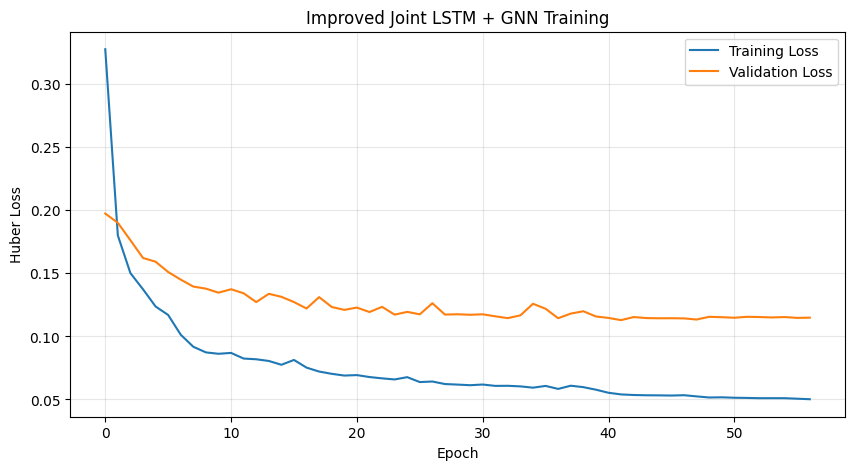

In [23]:
plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history.history["loss"],
    label="Training Loss",
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss",
)

plt.xlabel("Epoch")
plt.ylabel("Huber Loss")
plt.title(
    "Improved Joint LSTM + GNN Training"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 20. Inverse-transform predictions

In [24]:
def inverse_targets(
    scaled_values,
    scalers,
):
    result = np.zeros_like(
        scaled_values,
        dtype=np.float32,
    )

    for i, room in enumerate(ROOMS):

        result[:, i] = (
            scalers[room]
            .inverse_transform(
                scaled_values[
                    :,
                    i
                ].reshape(-1, 1)
            )
            .reshape(-1)
        )

    return result


pred_scaled = improved_stgnn.predict(
    X_test,
    batch_size=BATCH_SIZE,
    verbose=1,
)

actual = inverse_targets(
    Y_test,
    target_scalers,
)

predicted = inverse_targets(
    pred_scaled,
    target_scalers,
)

print(
    "Actual:",
    actual.shape
)

print(
    "Predicted:",
    predicted.shape
)

20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 302ms/step
Actual: (1251, 5)
Predicted: (1251, 5)


## 21. Evaluate all five rooms

In [25]:
metrics = []

for i, room in enumerate(ROOMS):

    y_true = actual[:, i]
    y_pred = predicted[:, i]

    mae = mean_absolute_error(
        y_true,
        y_pred,
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred,
        )
    )

    r2 = r2_score(
        y_true,
        y_pred,
    )

    metrics.append({
        "Room": room,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
    })


metrics_df = pd.DataFrame(
    metrics
)

average_row = pd.DataFrame([{
    "Room": "Average",
    "MAE": metrics_df["MAE"].mean(),
    "RMSE": metrics_df["RMSE"].mean(),
    "R2": metrics_df["R2"].mean(),
}])

metrics_df = pd.concat(
    [
        metrics_df,
        average_row,
    ],
    ignore_index=True,
)

display(metrics_df)

,Room,MAE,RMSE,R2
0,Room 1,0.775930,1.248205,-161.813583
1,Room 2,1.471285,3.798378,0.484085
2,Room 3,0.387915,0.665311,0.494927
3,Room 4,0.741369,1.099861,0.849866
4,Room 5,0.425697,0.642741,0.592850
5,Average,0.760439,1.490899,-31.878371


## 22. Complete Actual vs Predicted plot

This uses **every test value**, not only the first 200 samples.

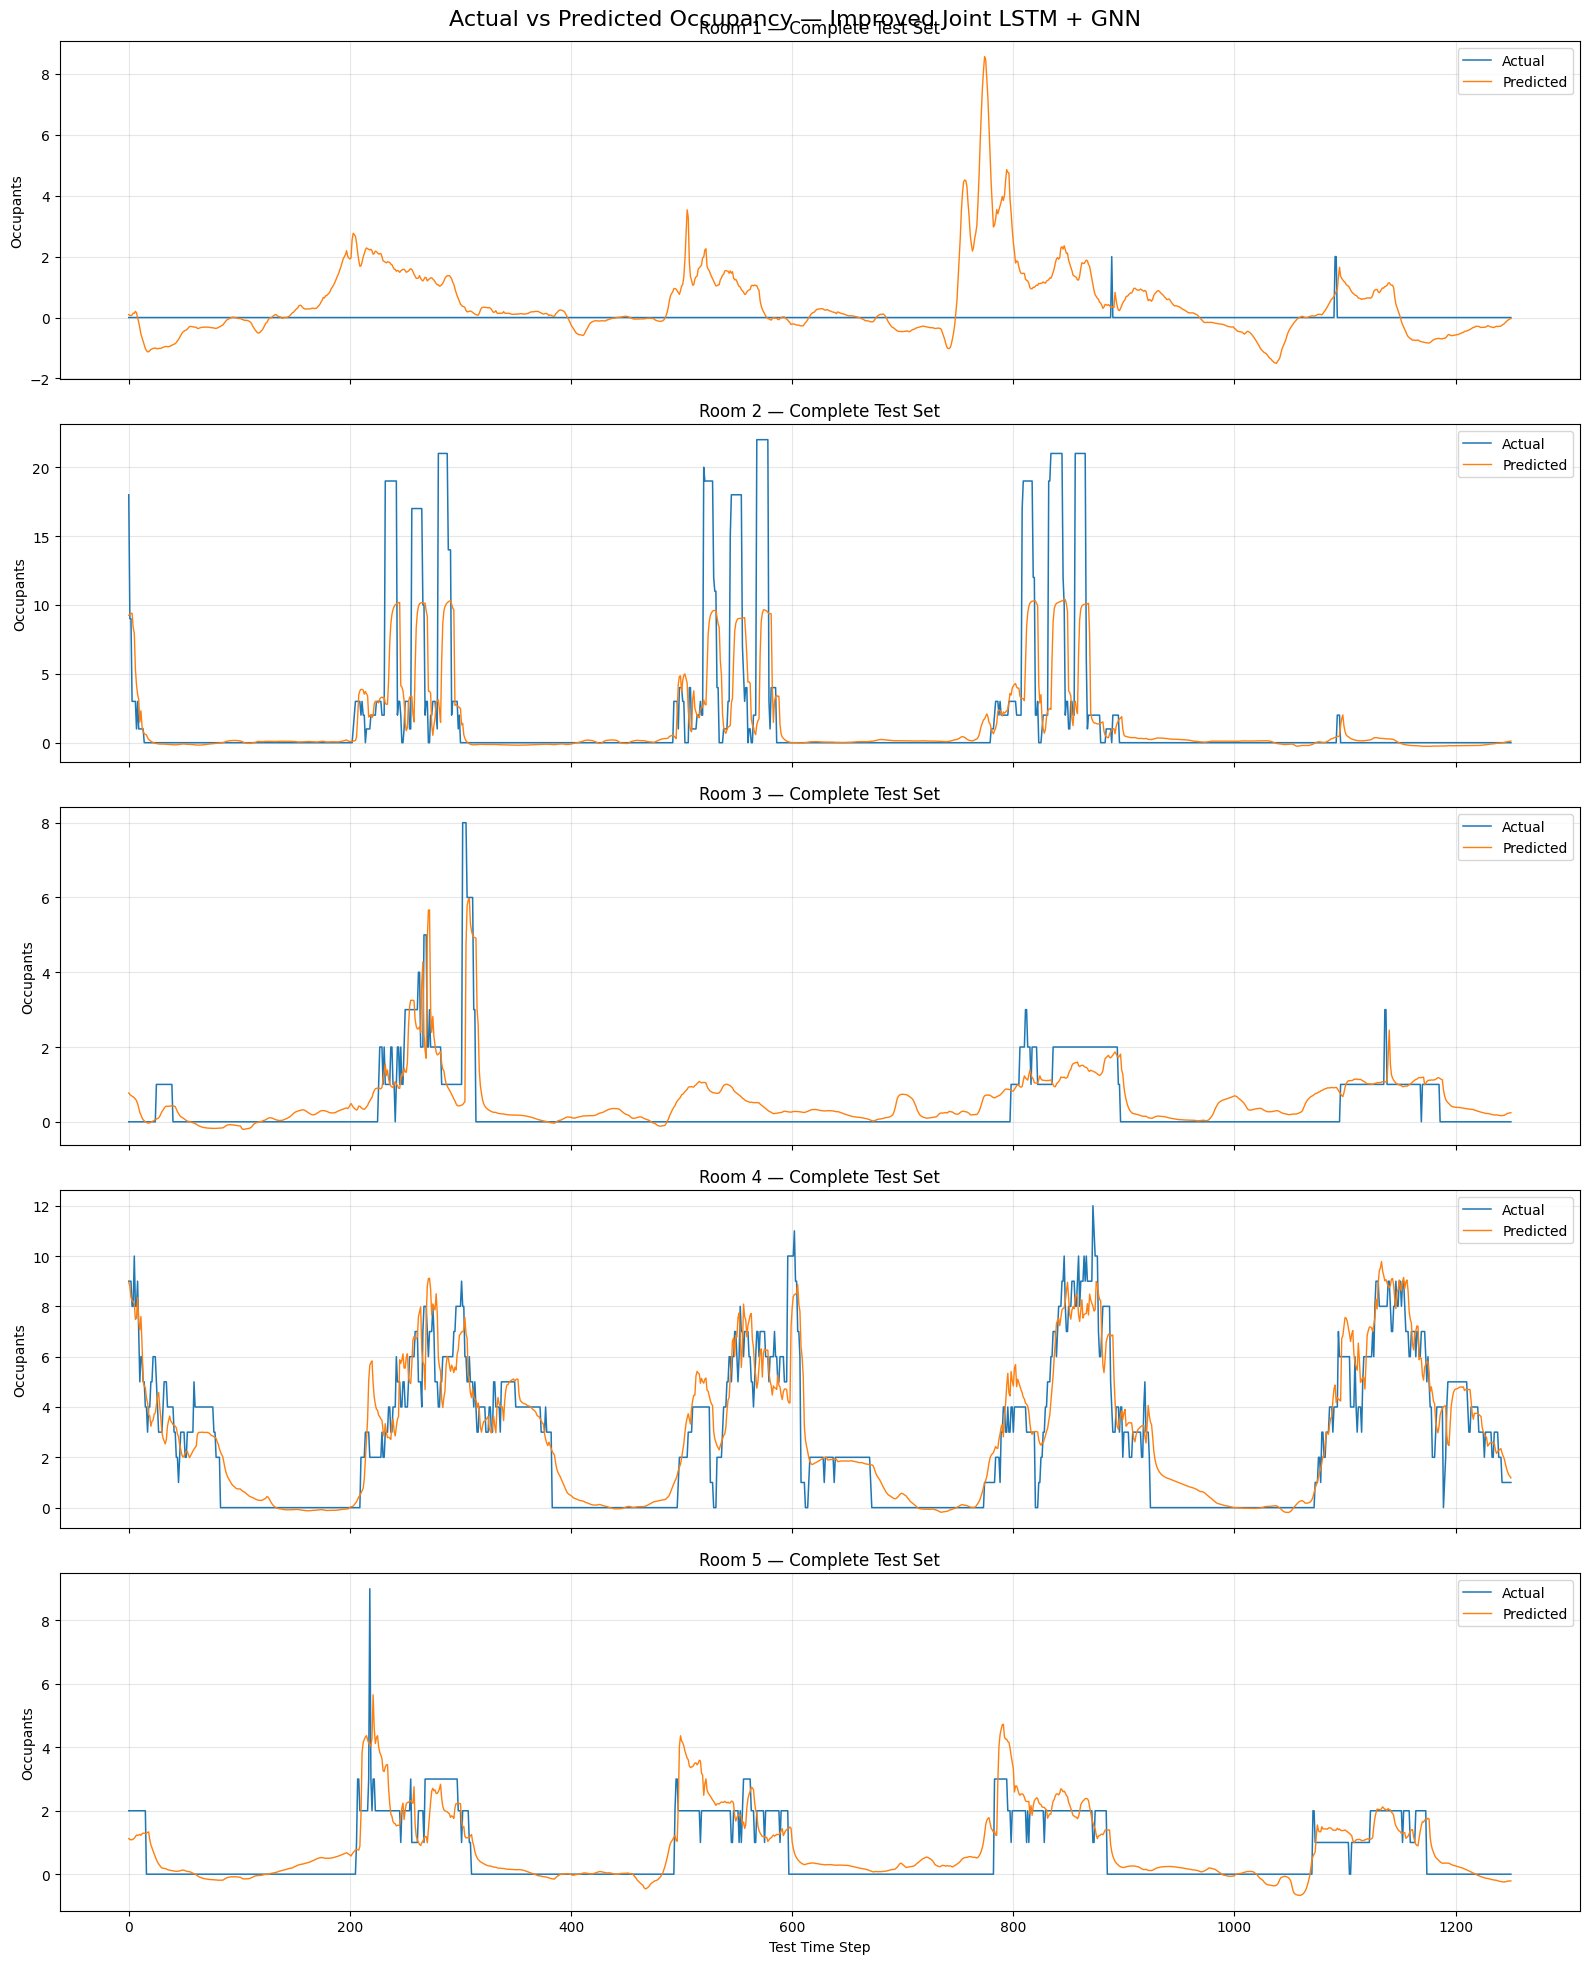

In [26]:
fig, axes = plt.subplots(
    N_ROOMS,
    1,
    figsize=(16, 20),
    sharex=True,
)

for i, room in enumerate(ROOMS):

    axes[i].plot(
        actual[:, i],
        label="Actual",
        linewidth=1.1,
    )

    axes[i].plot(
        predicted[:, i],
        label="Predicted",
        linewidth=1.0,
    )

    axes[i].set_title(
        f"{room} — Complete Test Set"
    )

    axes[i].set_ylabel(
        "Occupants"
    )

    axes[i].legend()
    axes[i].grid(alpha=0.3)


axes[-1].set_xlabel(
    "Test Time Step"
)

plt.suptitle(
    "Actual vs Predicted Occupancy — Improved Joint LSTM + GNN",
    fontsize=16,
)

plt.tight_layout()
plt.show()

## 23. Actual vs Predicted numerical table

Every test prediction is retained.

In [27]:
results = pd.DataFrame()

results["Timestamp"] = (
    common_index[
        test_positions
    ]
    .astype(str)
    .to_numpy()
)

for i, room in enumerate(ROOMS):

    results[
        f"{room} Actual"
    ] = actual[:, i]

    results[
        f"{room} Predicted"
    ] = predicted[:, i]

display(
    results
)

,Timestamp,Room 1 Actual,Room 1 Predicted,Room 2 Actual,Room 2 Predicted,Room 3 Actual,Room 3 Predicted,Room 4 Actual,Room 4 Predicted,Room 5 Actual,Room 5 Predicted
0,2021-12-17 07:45:00+00:00,-6.035914e-09,0.093835,1.800000e+01,9.252582,-3.038348e-08,0.769624,9.0,8.963654,2.000000e+00,1.121084
1,2021-12-17 07:50:00+00:00,-6.035914e-09,0.076868,9.000000e+00,9.312773,-3.038348e-08,0.737575,9.0,8.800071,2.000000e+00,1.096516
2,2021-12-17 07:55:00+00:00,-6.035914e-09,0.055590,9.000000e+00,9.380767,-3.038348e-08,0.701847,9.0,8.373770,2.000000e+00,1.082899
3,2021-12-17 08:00:00+00:00,-6.035914e-09,0.087056,3.000000e+00,9.395894,-3.038348e-08,0.684619,8.0,8.217752,2.000000e+00,1.087576
4,2021-12-17 08:05:00+00:00,-6.035914e-09,0.144062,3.000000e+00,8.356170,-3.038348e-08,0.668755,8.0,8.198968,2.000000e+00,1.106030
...,...,...,...,...,...,...,...,...,...,...,...
1246,2021-12-23 15:35:00+00:00,-6.035914e-09,-0.128068,1.015502e-08,0.063847,-3.038348e-08,0.207386,1.0,1.570856,-6.753697e-08,-0.230657
1247,2021-12-23 15:40:00+00:00,-6.035914e-09,-0.093020,1.015502e-08,0.081122,-3.038348e-08,0.225501,1.0,1.418690,-6.753697e-08,-0.217989
1248,2021-12-23 15:45:00+00:00,-6.035914e-09,-0.070033,1.015502e-08,0.095129,-3.038348e-08,0.231663,1.0,1.315771,-6.753697e-08,-0.214407
1249,2021-12-23 15:50:00+00:00,-6.035914e-09,-0.046809,1.015502e-08,0.107457,-3.038348e-08,0.240685,1.0,1.250147,-6.753697e-08,-0.212415


## 24. Prediction-error analysis

In [28]:
error_table = pd.DataFrame()

for i, room in enumerate(ROOMS):

    error_table[room] = (
        actual[:, i]
        - predicted[:, i]
    )

display(
    error_table.describe()
)

,Room 1,Room 2,Room 3,Room 4,Room 5
count,1251.000000,1251.000000,1251.000000,1251.000000,1251.000000
mean,-0.449786,0.649990,-0.165800,-0.192623,-0.151473
std,1.164815,3.743850,0.644578,1.083295,0.624887
min,-8.561521,-9.090491,-4.908882,-5.401314,-2.738588
25%,-0.965695,-0.184119,-0.344889,-0.666594,-0.348094
50%,-0.124353,-0.064691,-0.185826,-0.064137,-0.139019
75%,0.263945,0.147625,-0.035523,0.206435,0.091764
max,1.669599,20.683702,7.539642,5.842422,4.904411


## 25. MAE / RMSE / R² visualization

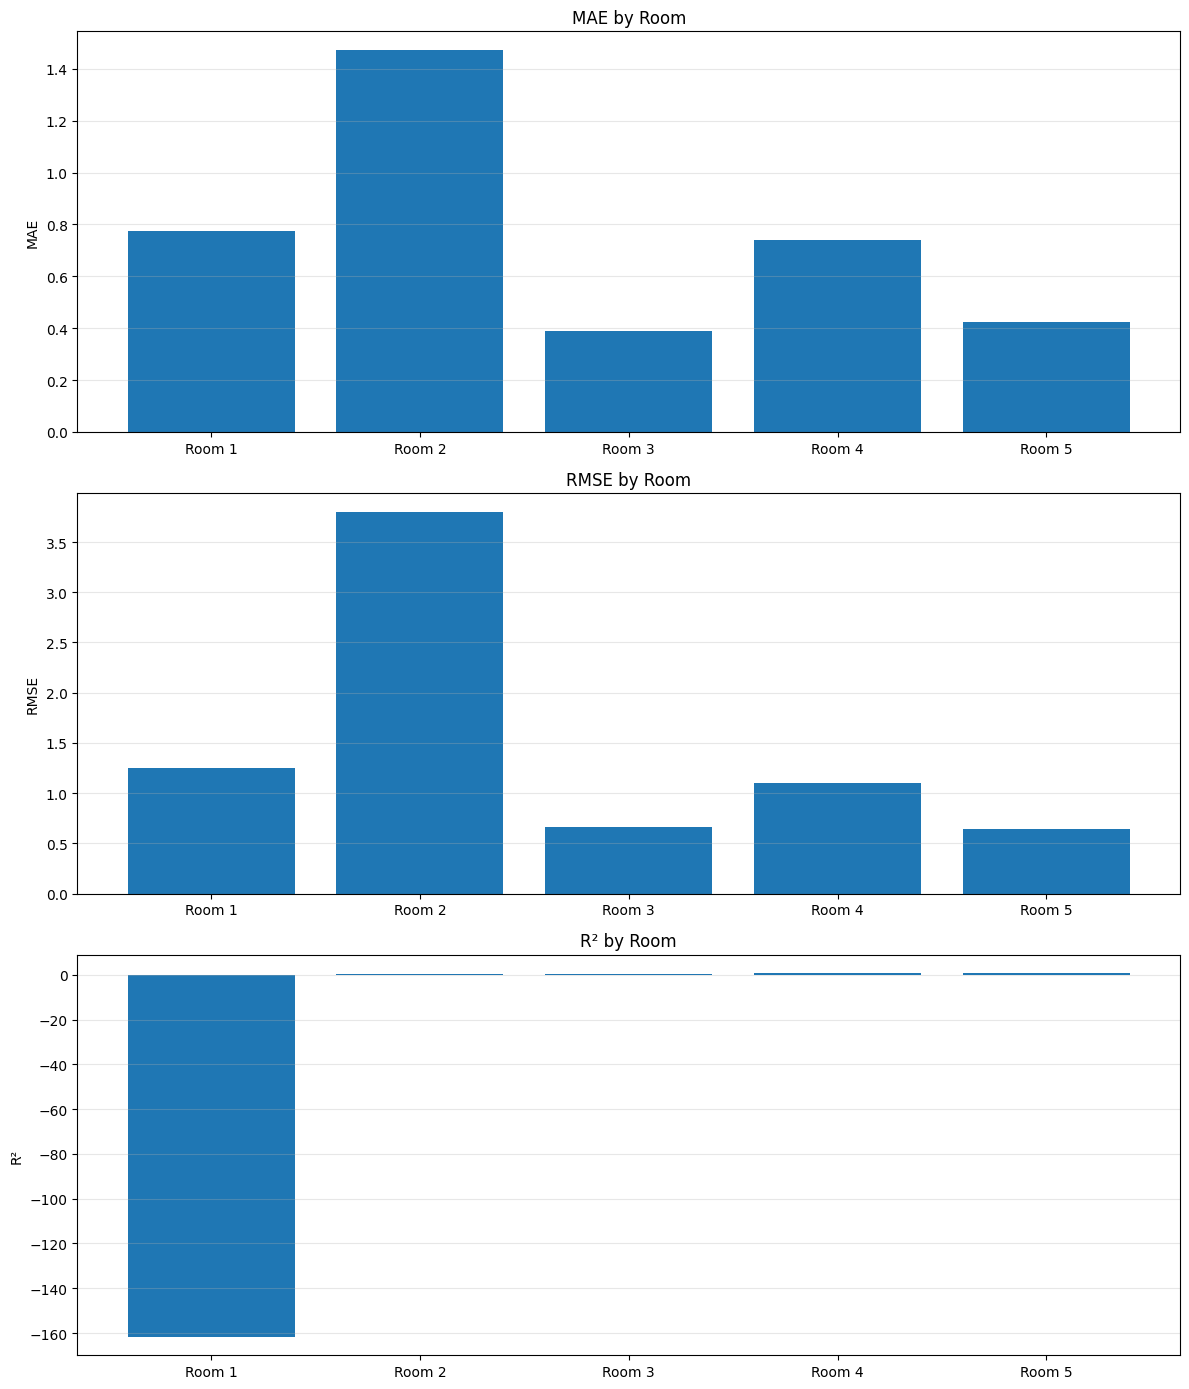

In [29]:
plot_metrics = metrics_df[
    metrics_df["Room"] != "Average"
].copy()

fig, axes = plt.subplots(
    3,
    1,
    figsize=(12, 14)
)

axes[0].bar(
    plot_metrics["Room"],
    plot_metrics["MAE"],
)

axes[0].set_title(
    "MAE by Room"
)

axes[0].set_ylabel(
    "MAE"
)

axes[0].grid(
    axis="y",
    alpha=0.3
)


axes[1].bar(
    plot_metrics["Room"],
    plot_metrics["RMSE"],
)

axes[1].set_title(
    "RMSE by Room"
)

axes[1].set_ylabel(
    "RMSE"
)

axes[1].grid(
    axis="y",
    alpha=0.3
)


axes[2].bar(
    plot_metrics["Room"],
    plot_metrics["R2"],
)

axes[2].set_title(
    "R² by Room"
)

axes[2].set_ylabel(
    "R²"
)

axes[2].grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

## 26. Save the trained model and preprocessing artifacts

The custom GraphConv layer is registered and serializable.

The notebook evaluates the trained model directly in memory, so no checkpoint reload is required for evaluation.

In [30]:
MODEL_PATH = os.path.join(
    OUTPUT_DIR,
    "improved_joint_stgnn_lstm_all_5_rooms.keras"
)

SCALERS_PATH = os.path.join(
    OUTPUT_DIR,
    "joint_lstm_gnn_target_scalers.joblib"
)

CONFIG_PATH = os.path.join(
    OUTPUT_DIR,
    "joint_lstm_gnn_config.json"
)

METRICS_PATH = os.path.join(
    OUTPUT_DIR,
    "joint_lstm_gnn_metrics.csv"
)

PREDICTIONS_PATH = os.path.join(
    OUTPUT_DIR,
    "joint_lstm_gnn_actual_vs_predicted.csv"
)


improved_stgnn.save(
    MODEL_PATH
)

joblib.dump(
    {
        "sensor_scalers": sensor_scalers,
        "target_scalers": target_scalers,
    },
    SCALERS_PATH,
)

with open(
    CONFIG_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        {
            "rooms": ROOMS,
            "seq_len": SEQ_LEN,
            "horizon": HORIZON,
            "input_features": INPUT_FEATURES,
            "common_sensor_features": COMMON_SENSOR_FEATURES,
            "time_features": TIME_FEATURES,
            "adjacency": ADJACENCY.tolist(),
            "gnn_hidden": GNN_HIDDEN,
            "lstm_units": LSTM_UNITS,
            "architecture": (
                "GraphConv at every timestep -> "
                "shared two-layer LSTM -> "
                "final GraphConv -> "
                "shared room prediction head"
            ),
        },
        f,
        indent=2,
    )

metrics_df.to_csv(
    METRICS_PATH,
    index=False,
)

results.to_csv(
    PREDICTIONS_PATH,
    index=False,
)

print("Saved:")
print(MODEL_PATH)
print(SCALERS_PATH)
print(CONFIG_PATH)
print(METRICS_PATH)
print(PREDICTIONS_PATH)

Saved:
/content/joint_lstm_gnn_results/improved_joint_stgnn_lstm_all_5_rooms.keras
/content/joint_lstm_gnn_results/joint_lstm_gnn_target_scalers.joblib
/content/joint_lstm_gnn_results/joint_lstm_gnn_config.json
/content/joint_lstm_gnn_results/joint_lstm_gnn_metrics.csv
/content/joint_lstm_gnn_results/joint_lstm_gnn_actual_vs_predicted.csv


## 27. Final model summary

The final model is a **single joint LSTM + GNN architecture** for all five rooms.

It should be described as:

> A joint spatio-temporal graph neural network was developed for five-room occupant-count forecasting. Synchronized environmental and historical occupancy observations from all five rooms are represented as graph nodes over a temporal input window. Graph convolution is performed across the room nodes at each historical timestamp, allowing cross-room information exchange before temporal encoding. A shared two-layer LSTM then learns temporal dependencies for the graph-informed room representations. A further graph-convolution block performs spatial refinement before a shared node-wise prediction head produces occupancy-count forecasts for all five rooms simultaneously.

### Key properties

- One model
- One optimizer
- One training process
- All five rooms in every sample
- Cross-room graph message passing
- Shared temporal LSTM parameters
- Simultaneous prediction of five occupancy counts
- Training-only scaling
- Chronological evaluation
- Historical occupancy used only as past input

In [31]:
# ============================================================
# CURRENT LSTM + GNN PERFORMANCE
# ============================================================

pred_scaled = improved_stgnn.predict(
    X_test,
    batch_size=BATCH_SIZE,
    verbose=1
)

actual = inverse_targets(
    Y_test,
    target_scalers
)

predicted = inverse_targets(
    pred_scaled,
    target_scalers
)

rows = []

for i, room in enumerate(ROOMS):

    y_true = actual[:, i]
    y_pred = predicted[:, i]

    rows.append({
        "Room": room,
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        )
    })

results = pd.DataFrame(rows)

results.loc[len(results)] = {
    "Room": "Average",
    "R2": results["R2"].mean(),
    "MAE": results["MAE"].mean(),
    "RMSE": results["RMSE"].mean()
}

display(results)

20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step


,Room,R2,MAE,RMSE
0,Room 1,-161.813583,0.775930,1.248205
1,Room 2,0.484085,1.471285,3.798378
2,Room 3,0.494927,0.387915,0.665311
3,Room 4,0.849866,0.741369,1.099861
4,Room 5,0.592850,0.425697,0.642741
5,Average,-31.878371,0.760439,1.490899


In [32]:
# ============================================================
# NEXT LSTM + GNN IMPROVEMENT
# JOINT 5-ROOM OUTPUT HEAD + RESIDUAL PERSISTENCE
#
# Your current model:
# Room 1 R2  = -152.96
# Room 2 R2  =    0.48
# Room 3 R2  =    0.49
# Room 4 R2  =    0.85
# Room 5 R2  =    0.58
#
# Main architectural change:
# The previous output head predicts each room independently
# after graph processing.
#
# This version creates ONE JOINT REPRESENTATION of all 5 rooms
# and predicts all 5 occupancies together.
#
# ============================================================

# ------------------------------------------------------------
# JOINT LSTM + GNN MODEL
# ------------------------------------------------------------

def build_joint_output_stgnn(
    seq_len,
    n_nodes,
    n_features,
    gnn_hidden=96,
    lstm_units=128,
    dropout=0.20,
):

    inputs = layers.Input(
        shape=(seq_len, n_nodes, n_features),
        name="all_rooms_history"
    )

    # ========================================================
    # SPATIAL BLOCK 1
    # ========================================================

    x = layers.TimeDistributed(
        GraphConv(
            gnn_hidden,
            ADJACENCY,
            activation="relu",
            name="graph_1"
        ),
        name="graph_over_time_1"
    )(inputs)

    x = layers.LayerNormalization(
        axis=-1
    )(x)

    x = layers.Dropout(
        dropout
    )(x)

    # ========================================================
    # SPATIAL BLOCK 2 + RESIDUAL
    # ========================================================

    x2 = layers.TimeDistributed(
        GraphConv(
            gnn_hidden,
            ADJACENCY,
            activation="relu",
            name="graph_2"
        ),
        name="graph_over_time_2"
    )(x)

    x2 = layers.LayerNormalization(
        axis=-1
    )(x2)

    x = layers.Add()([
        x,
        x2
    ])

    x = layers.Activation(
        "relu"
    )(x)

    x = layers.Dropout(
        dropout
    )(x)

    # ========================================================
    # ROOM-FIRST FOR SHARED LSTM
    # [B,T,N,H] -> [B,N,T,H]
    # ========================================================

    x = layers.Permute(
        (2, 1, 3),
        name="rooms_first"
    )(x)

    # ========================================================
    # SHARED LSTM 1
    # ========================================================

    x = layers.TimeDistributed(
        layers.LSTM(
            lstm_units,
            return_sequences=True,
            dropout=0.10,
            name="shared_lstm_1"
        )
    )(x)

    x = layers.LayerNormalization(
        axis=-1
    )(x)

    # ========================================================
    # SHARED LSTM 2
    # ========================================================

    x = layers.TimeDistributed(
        layers.LSTM(
            lstm_units,
            return_sequences=False,
            dropout=0.10,
            name="shared_lstm_2"
        )
    )(x)

    # [B,5,LSTM]
    x = layers.LayerNormalization(
        axis=-1
    )(x)

    x = layers.Dropout(
        dropout
    )(x)

    # ========================================================
    # FINAL GRAPH BLOCK
    # ========================================================

    graph_x = GraphConv(
        gnn_hidden,
        ADJACENCY,
        activation="relu",
        name="final_graph"
    )(x)

    graph_x = layers.LayerNormalization(
        axis=-1
    )(graph_x)

    # ========================================================
    # RESIDUAL FUSION
    # ========================================================

    temporal_x = layers.Dense(
        gnn_hidden,
        activation=None,
        name="temporal_projection"
    )(x)

    x = layers.Add()([
        temporal_x,
        graph_x
    ])

    x = layers.Activation(
        "relu"
    )(x)

    x = layers.LayerNormalization(
        axis=-1
    )(x)

    # ========================================================
    # SAVE LAST OBSERVED OCCUPANCY
    # ========================================================
    #
    # Last input feature = scaled historical occupancy
    #
    # [B,T,N,F]
    #       ↓
    # [B,N]
    #
    # ========================================================

    last_occ = layers.Lambda(
        lambda z: z[:, -1, :, -1],
        name="last_observed_occupancy"
    )(inputs)

    # ========================================================
    # JOINT ROOM REPRESENTATION
    #
    # [B,5,H]
    #    ↓
    # [B,5*H]
    #
    # ========================================================

    x = layers.Flatten(
        name="joint_room_embedding"
    )(x)

    x = layers.Dense(
        256,
        activation="relu",
        name="joint_dense_1"
    )(x)

    x = layers.BatchNormalization(
        name="joint_batch_norm"
    )(x)

    x = layers.Dropout(
        0.25
    )(x)

    x = layers.Dense(
        128,
        activation="relu",
        name="joint_dense_2"
    )(x)

    x = layers.Dropout(
        0.15
    )(x)

    # ========================================================
    # JOINT DELTA PREDICTION
    # ========================================================

    delta = layers.Dense(
        n_nodes,
        activation=None,
        name="joint_occupancy_delta"
    )(x)

    # ========================================================
    # PERSISTENCE RESIDUAL
    #
    # predicted occupancy =
    # last occupancy + learned change
    # ========================================================

    outputs = layers.Add(
        name="joint_residual_output"
    )([
        last_occ,
        delta
    ])

    return Model(
        inputs=inputs,
        outputs=outputs,
        name="Joint_Output_STGNN_LSTM_5Rooms"
    )


# ============================================================
# CREATE MODEL
# ============================================================

joint_stgnn = build_joint_output_stgnn(
    seq_len=SEQ_LEN,
    n_nodes=N_ROOMS,
    n_features=X_train.shape[-1],
    gnn_hidden=96,
    lstm_units=128,
    dropout=0.20
)

# ============================================================
# COMPILE
# ============================================================

joint_stgnn.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=2e-4,
        clipnorm=1.0
    ),
    loss=tf.keras.losses.Huber(
        delta=1.0
    ),
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(
            name="mae"
        ),
        tf.keras.metrics.RootMeanSquaredError(
            name="rmse"
        )
    ]
)

# ============================================================
# SHAPE TEST
# ============================================================

test_output = joint_stgnn(
    X_train[:2],
    training=False
)

print("Input :", X_train[:2].shape)
print("Output:", test_output.shape)

assert tuple(test_output.shape) == (2, 5)

joint_stgnn.summary()

Input : (2, 12, 5, 13)
Output: (2, 5)


Model: "Joint_Output_STGNN_LSTM_5Rooms"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ all_rooms_history   │ (None, 12, 5, 13) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ graph_over_time_1   │ (None, 12, 5, 96) │      2,617 │ all_rooms_histor… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 12, 5, 96) │        192 │ graph_over_time_… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 12, 5, 96) │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ graph_over_time_2   │ (None, 12, 5, 96) │     18,553 │ dropout[0][0]     │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 12, 5, 96) │        192 │ graph_over_time_… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 12, 5, 96) │          0 │ dropout[0][0],    │
│                     │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 12, 5, 96) │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 12, 5, 96) │          0 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rooms_first         │ (None, 5, 12, 96) │          0 │ dropout_1[0][0]   │
│ (Permute)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed    │ (None, 5, 12,     │    115,200 │ rooms_first[0][0] │
│ (TimeDistributed)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 5, 12,     │        256 │ time_distributed… │
│ (LayerNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed_1  │ (None, 5, 128)    │    131,584 │ layer_normalizat… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 5, 128)    │        256 │ time_distributed… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 5, 128)    │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ final_graph         │ (None, 5, 96)     │     24,697 │ dropout_2[0][0]   │
│ (GraphConv)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_projection │ (None, 5, 96)     │     12,384 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 5, 96)     │        192 │ final_graph[0][0

 Total params: 464,016 (1.77 MB)

 Trainable params: 463,429 (1.77 MB)

 Non-trainable params: 587 (2.29 KB)

In [33]:
# ============================================================
# TRAIN
# ============================================================

callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        min_delta=1e-4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

joint_history = joint_stgnn.fit(
    X_train,
    Y_train,
    validation_data=(
        X_val,
        Y_val
    ),
    epochs=60,
    batch_size=64,
    shuffle=False,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 76s 513ms/step - loss: 0.5518 - mae: 0.9388 - rmse: 1.2043 - val_loss: 0.2320 - val_mae: 0.5365 - val_rmse: 0.9065 - learning_rate: 2.0000e-04
Epoch 2/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 43s 463ms/step - loss: 0.3317 - mae: 0.6804 - rmse: 0.8783 - val_loss: 0.1512 - val_mae: 0.4013 - val_rmse: 0.8062 - learning_rate: 2.0000e-04
Epoch 3/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 44s 476ms/step - loss: 0.2180 - mae: 0.5297 - rmse: 0.6981 - val_loss: 0.1195 - val_mae: 0.3332 - val_rmse: 0.7659 - learning_rate: 2.0000e-04
Epoch 4/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 43s 463ms/step - loss: 0.1517 - mae: 0.4298 - rmse: 0.5760 - val_loss: 0.1061 - val_mae: 0.2972 - val_rmse: 0.7426 - learning_rate: 2.0000e-04
Epoch 5/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 43s 466ms/step - loss: 0.1257 - mae: 0.3834 - rmse: 0.5292 - val_loss: 0.0966 - val_mae: 0.2657 - val_rmse: 0.7245 - learning_rate: 2.0000e-04
Epoch 6/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 81s 457ms/step - loss: 0.1074 - mae: 0.3484 - rmse: 0.488

In [34]:
# ============================================================
# EVALUATE CURRENT JOINT LSTM + GNN
# ============================================================

pred_scaled = joint_stgnn.predict(
    X_test,
    batch_size=64,
    verbose=1
)

actual_joint = inverse_targets(
    Y_test,
    target_scalers
)

predicted_joint = inverse_targets(
    pred_scaled,
    target_scalers
)

rows = []

for i, room in enumerate(ROOMS):

    yt = actual_joint[:, i]
    yp = predicted_joint[:, i]

    rows.append({
        "Room": room,
        "R2": r2_score(yt, yp),
        "MAE": mean_absolute_error(yt, yp),
        "RMSE": np.sqrt(
            mean_squared_error(yt, yp)
        )
    })

joint_metrics = pd.DataFrame(rows)

joint_metrics.loc[len(joint_metrics)] = {
    "Room": "Average",
    "R2": joint_metrics["R2"].mean(),
    "MAE": joint_metrics["MAE"].mean(),
    "RMSE": joint_metrics["RMSE"].mean()
}

display(joint_metrics)

20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 260ms/step


,Room,R2,MAE,RMSE
0,Room 1,-30.047382,0.465324,0.545071
1,Room 2,0.563966,1.034170,3.491957
2,Room 3,0.472497,0.429092,0.679924
3,Room 4,0.863345,0.664895,1.049328
4,Room 5,0.733346,0.257940,0.520155
5,Average,-5.482846,0.570284,1.257287


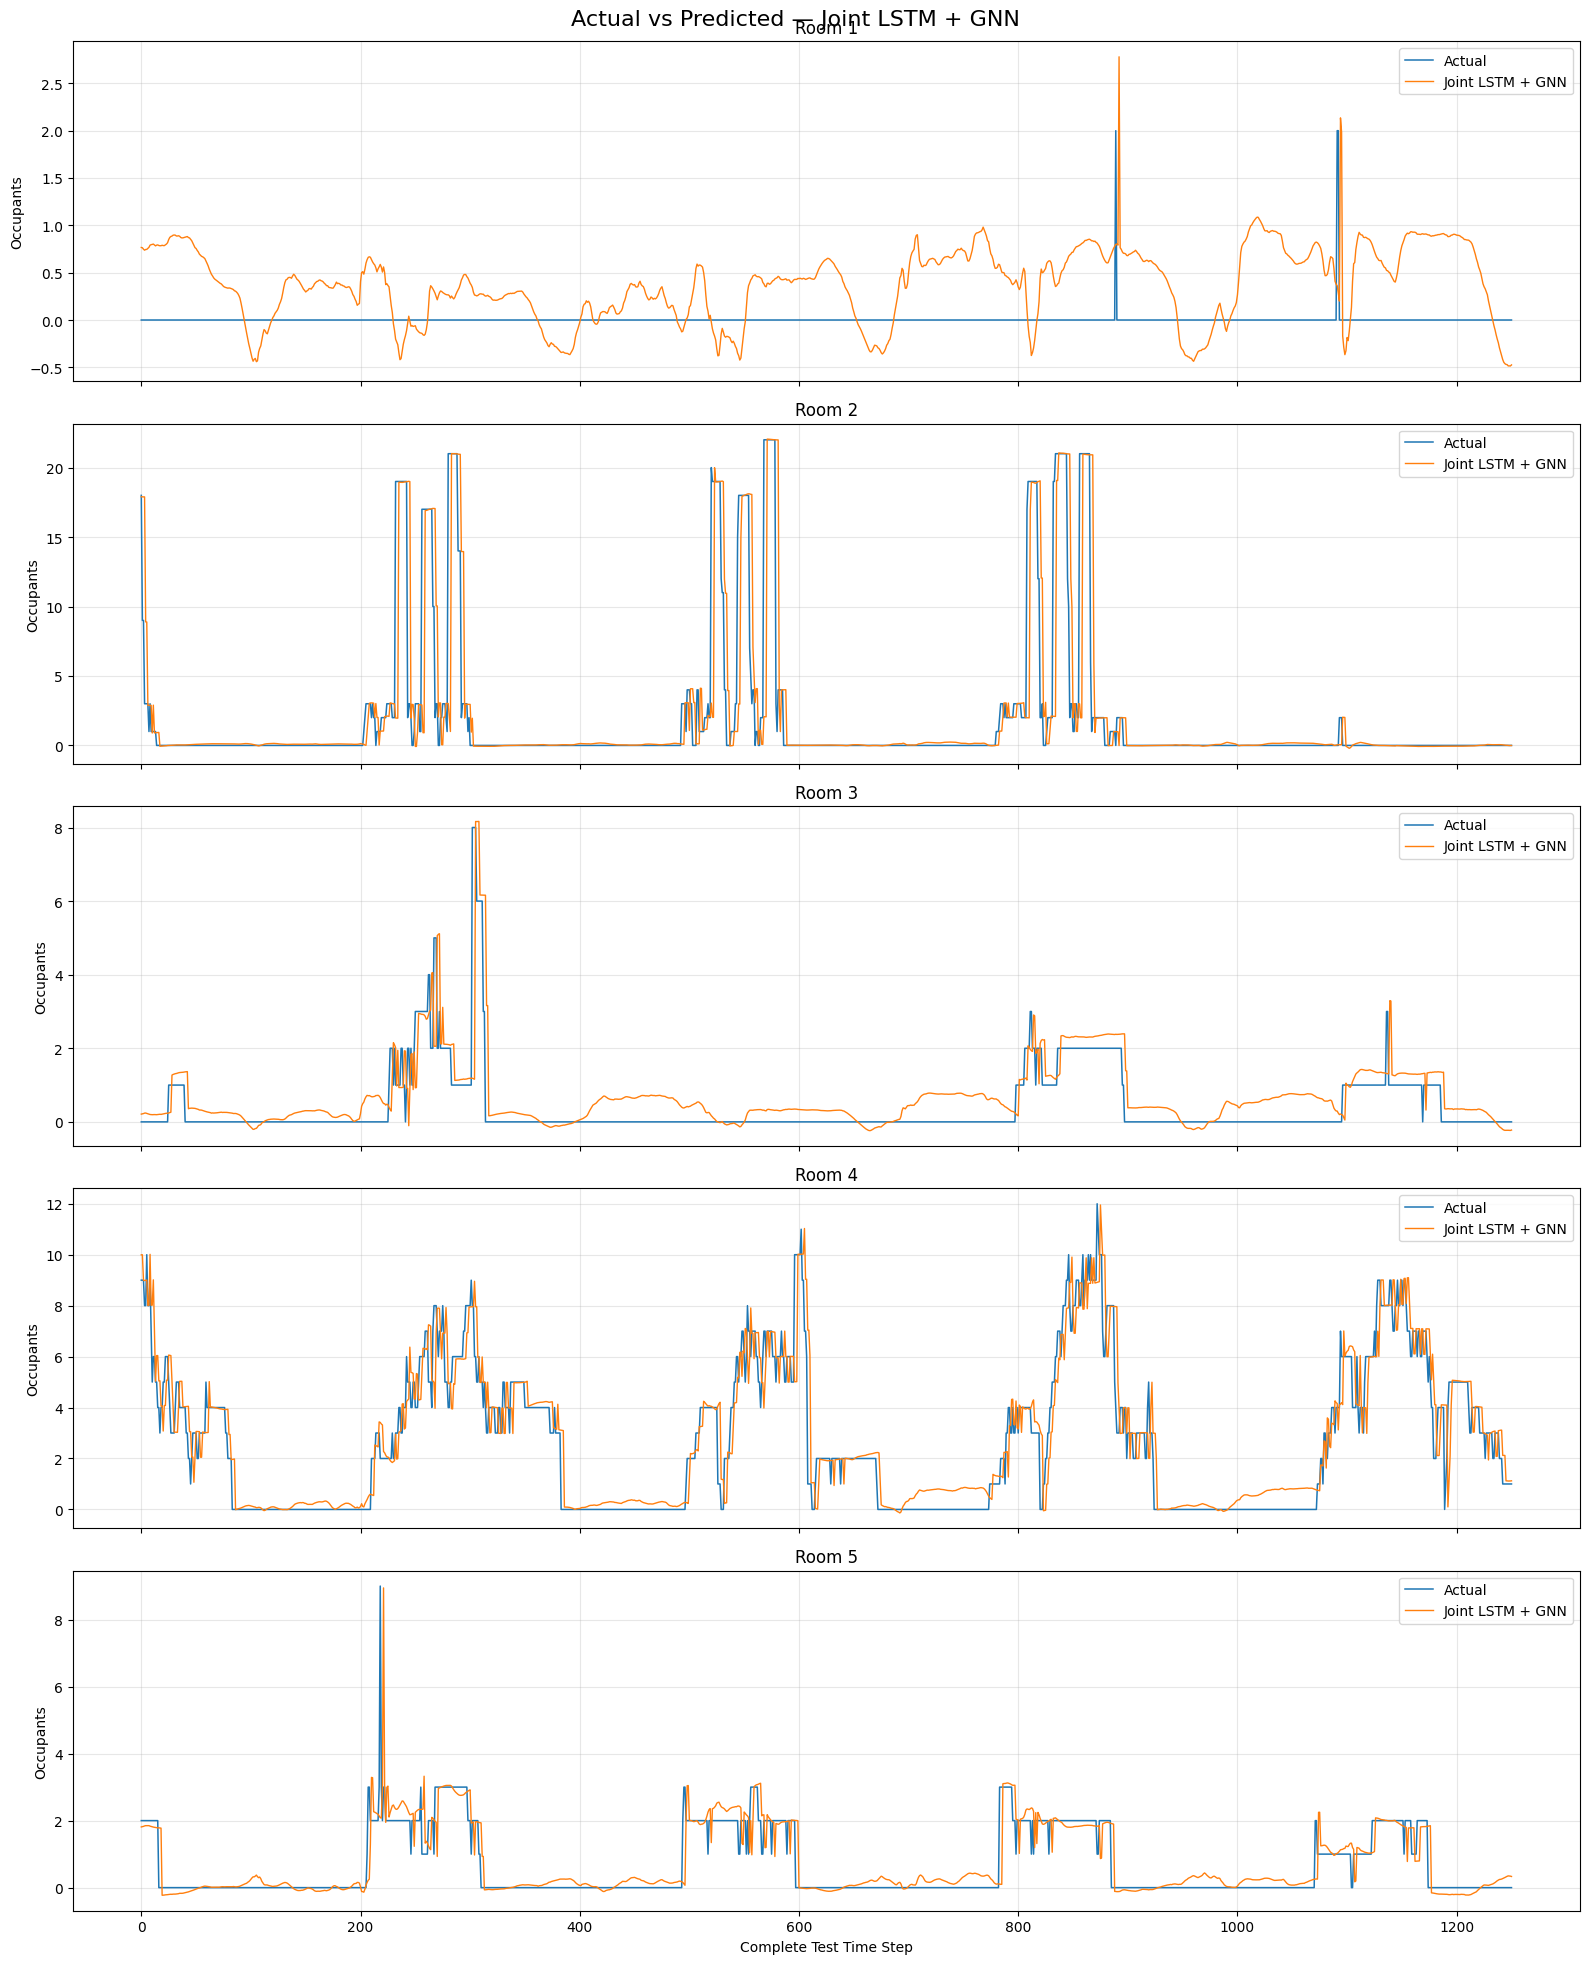

In [35]:
# ============================================================
# COMPLETE ACTUAL vs PREDICTED
# ============================================================

fig, axes = plt.subplots(
    5,
    1,
    figsize=(16, 20),
    sharex=True
)

for i, room in enumerate(ROOMS):

    axes[i].plot(
        actual_joint[:, i],
        label="Actual",
        linewidth=1.1
    )

    axes[i].plot(
        predicted_joint[:, i],
        label="Joint LSTM + GNN",
        linewidth=1.0
    )

    axes[i].set_title(
        room
    )

    axes[i].set_ylabel(
        "Occupants"
    )

    axes[i].legend()
    axes[i].grid(alpha=0.3)

axes[-1].set_xlabel(
    "Complete Test Time Step"
)

plt.suptitle(
    "Actual vs Predicted — Joint LSTM + GNN",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [36]:
# ============================================================
# COMPILE + TRAIN JOINT LSTM + GNN
# ============================================================

joint_stgnn.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=2e-4,
        clipnorm=1.0
    ),
    loss=tf.keras.losses.Huber(
        delta=1.0
    ),
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="mae"),
        tf.keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        min_delta=1e-4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

joint_history = joint_stgnn.fit(
    X_train,
    Y_train,
    validation_data=(X_val, Y_val),
    epochs=60,
    batch_size=64,
    shuffle=False,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 71s 475ms/step - loss: 0.0548 - mae: 0.1922 - rmse: 0.3610 - val_loss: 0.0830 - val_mae: 0.2036 - val_rmse: 0.7071 - learning_rate: 2.0000e-04
Epoch 2/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 41s 443ms/step - loss: 0.0532 - mae: 0.1835 - rmse: 0.3560 - val_loss: 0.0856 - val_mae: 0.2168 - val_rmse: 0.7122 - learning_rate: 2.0000e-04
Epoch 3/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 43s 463ms/step - loss: 0.0523 - mae: 0.1767 - rmse: 0.3539 - val_loss: 0.0808 - val_mae: 0.1835 - val_rmse: 0.7043 - learning_rate: 2.0000e-04
Epoch 4/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 42s 452ms/step - loss: 0.0513 - mae: 0.1706 - rmse: 0.3510 - val_loss: 0.0824 - val_mae: 0.1940 - val_rmse: 0.7074 - learning_rate: 2.0000e-04
Epoch 5/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 42s 454ms/step - loss: 0.0507 - mae: 0.1650 - rmse: 0.3496 - val_loss: 0.0857 - val_mae: 0.2094 - val_rmse: 0.7120 - learning_rate: 2.0000e-04
Epoch 6/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 42s 455ms/step - loss: 0.0504 - mae: 0.1614 - rmse: 0.348

In [40]:
joint_stgnn.save(
    "joint_lstm_gnn_all_5_rooms.keras"
)

print("Model saved successfully.")

Model saved successfully.


In [ ]:
# ============================================================
# ROUND LSTM + GNN PREDICTIONS TO WHOLE OCCUPANT COUNTS
# ============================================================

# Predict
pred_scaled = joint_stgnn.predict(
    X_test[:2000],
    batch_size=64,
    verbose=1
)

# Convert back to original occupancy scale
actual = inverse_targets(
    Y_test[:2000],
    target_scalers
)

predicted = inverse_targets(
    pred_scaled,
    target_scalers
)

# ------------------------------------------------------------
# Convert predictions to realistic whole-number occupancy
# ------------------------------------------------------------

predicted_whole = np.rint(predicted).astype(int)

# Occupancy cannot be negative
predicted_whole = np.maximum(
    predicted_whole,
    0
)

# Actual occupancy also shown as whole numbers
actual_whole = np.rint(actual).astype(int)

# ------------------------------------------------------------
# Show some predictions
# ------------------------------------------------------------

results = pd.DataFrame()

for i, room in enumerate(ROOMS):
    results[f"{room} Actual"] = actual_whole[:, i]
    results[f"{room} Predicted"] = predicted_whole[:, i]

display(results.head(50))

20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 101ms/step


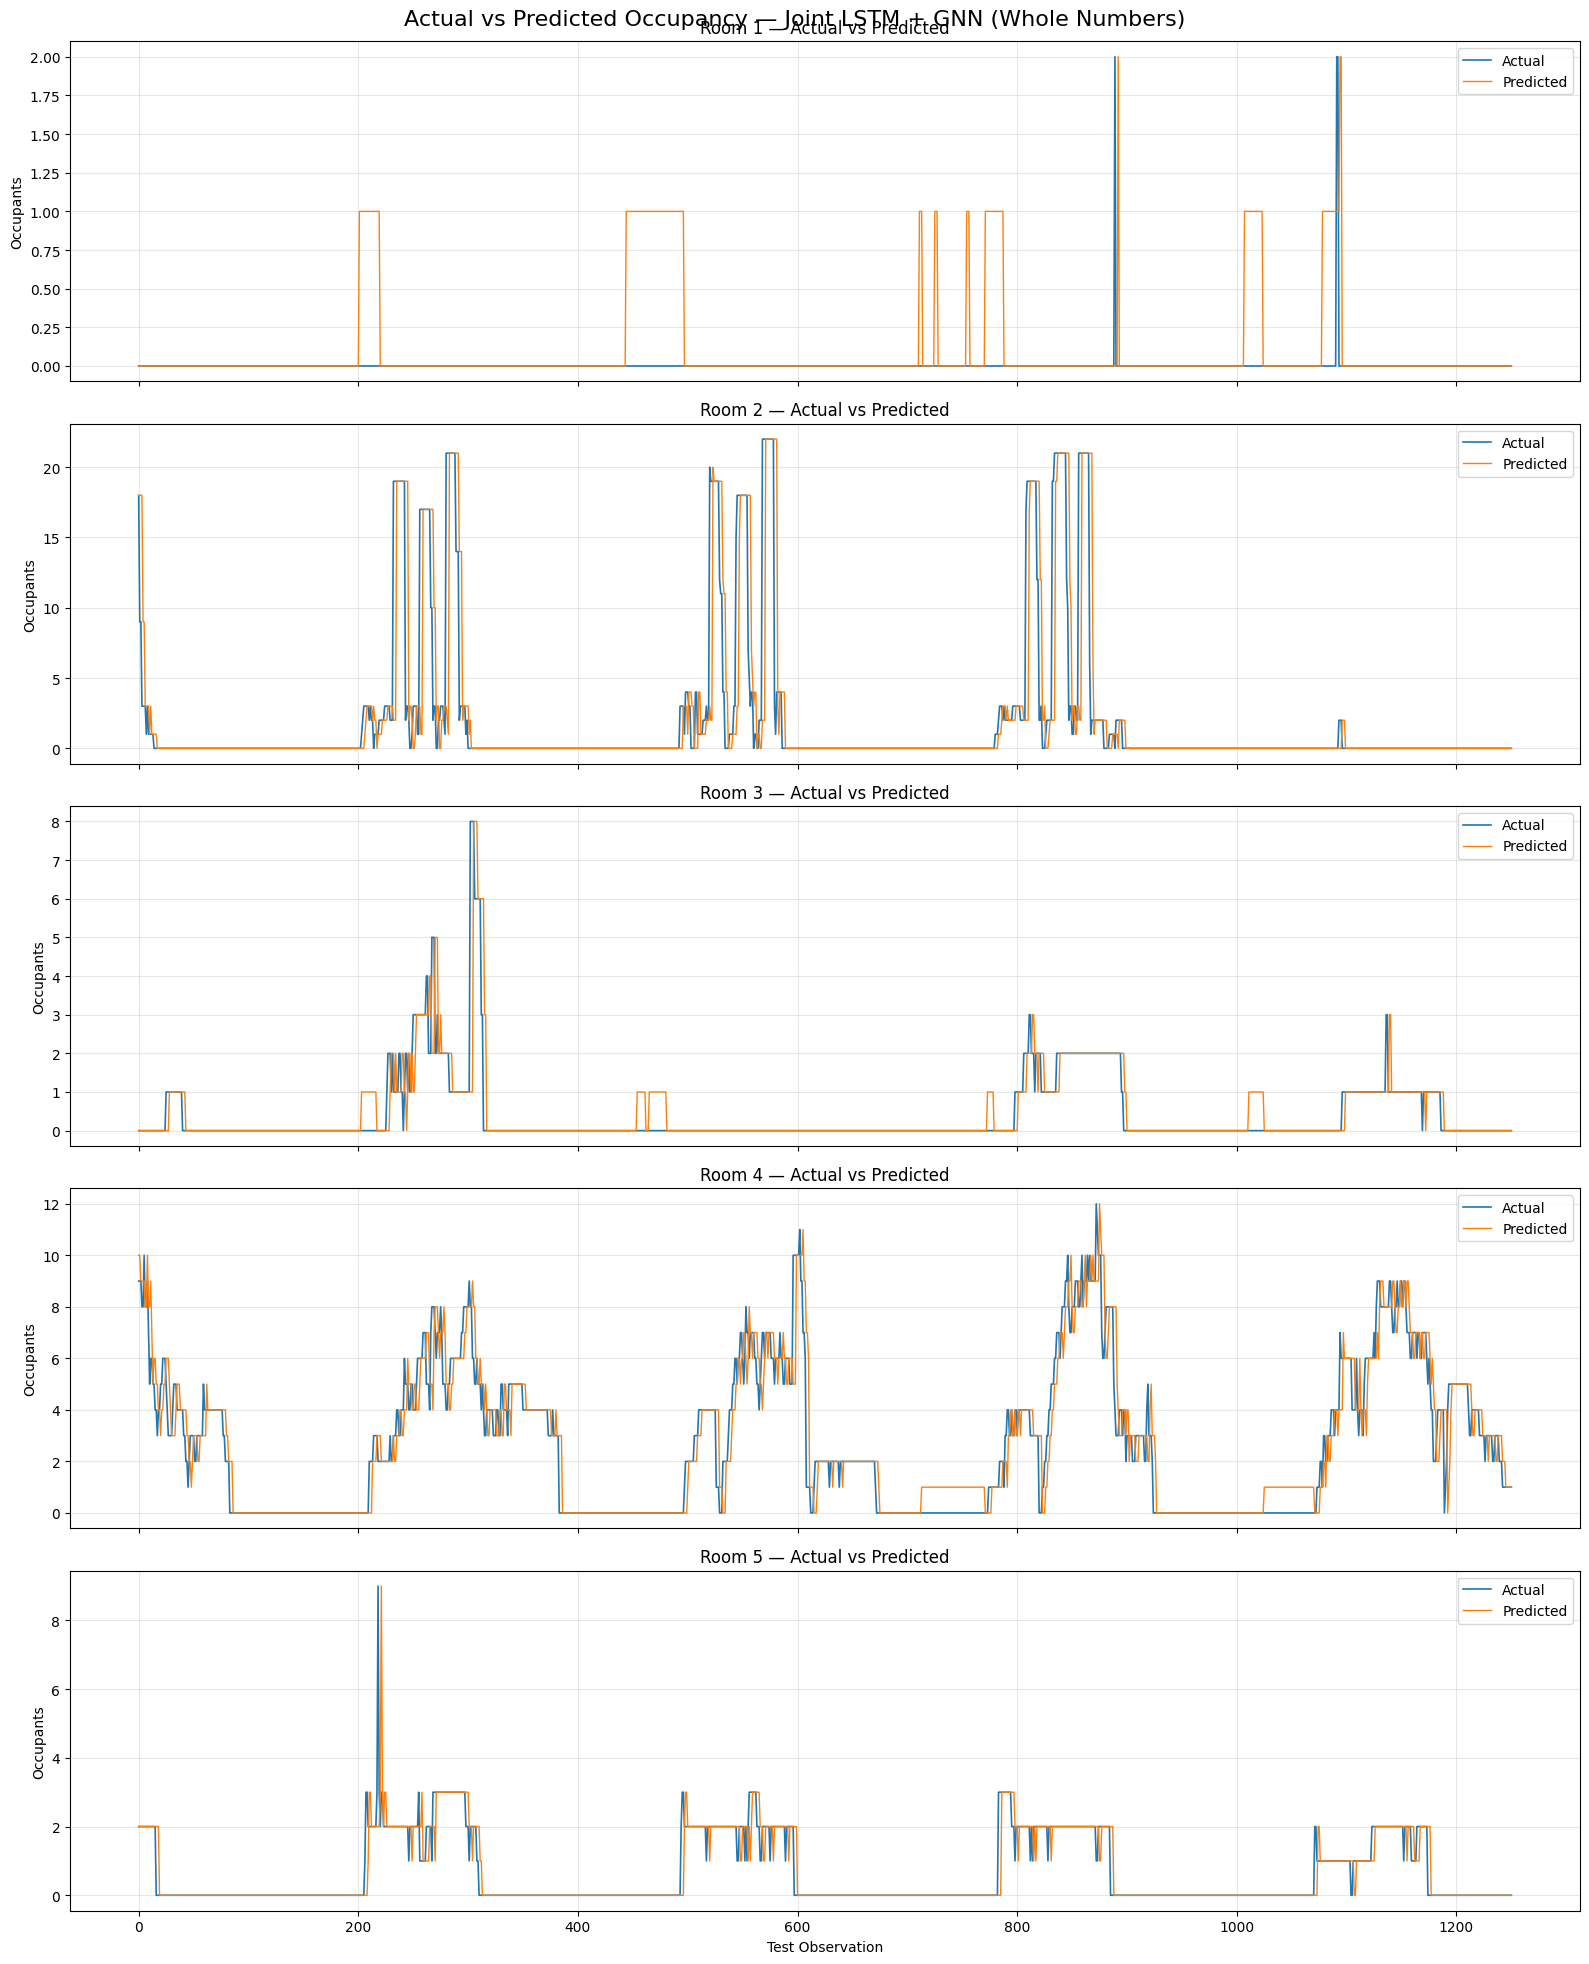

,Room 1 Actual,Room 1 Predicted,Room 2 Actual,Room 2 Predicted,Room 3 Actual,Room 3 Predicted,Room 4 Actual,Room 4 Predicted,Room 5 Actual,Room 5 Predicted
0,0,0,18,18,0,0,9,10,2,2
1,0,0,9,18,0,0,9,10,2,2
2,0,0,9,18,0,0,9,9,2,2
3,0,0,3,18,0,0,8,9,2,2
4,0,0,3,9,0,0,8,9,2,2
...,...,...,...,...,...,...,...,...,...,...
1246,0,0,0,0,0,0,1,1,0,0
1247,0,0,0,0,0,0,1,1,0,0
1248,0,0,0,0,0,0,1,1,0,0
1249,0,0,0,0,0,0,1,1,0,0



✓ Plotted 1251 observations using whole-number occupancy.


In [39]:
# ============================================================
# ACTUAL vs PREDICTED — WHOLE-NUMBER OCCUPANCY
# JOINT LSTM + GNN — FIRST 2000 TEST OBSERVATIONS
# ============================================================

N = min(2000, len(X_test))

# Predict
pred_scaled = joint_stgnn.predict(
    X_test[:N],
    batch_size=64,
    verbose=1
)

# Convert back to original occupancy scale
actual = inverse_targets(
    Y_test[:N],
    target_scalers
)

predicted = inverse_targets(
    pred_scaled,
    target_scalers
)

# Convert both to whole numbers
actual_whole = np.rint(actual).astype(int)
predicted_whole = np.rint(predicted).astype(int)

# Occupancy cannot be negative
actual_whole = np.maximum(actual_whole, 0)
predicted_whole = np.maximum(predicted_whole, 0)

# ============================================================
# PLOT
# ============================================================

fig, axes = plt.subplots(
    5,
    1,
    figsize=(16, 20),
    sharex=True
)

for i, room in enumerate(ROOMS):

    axes[i].plot(
        actual_whole[:, i],
        label="Actual",
        linewidth=1.2
    )

    axes[i].plot(
        predicted_whole[:, i],
        label="Predicted",
        linewidth=1.0
    )

    axes[i].set_title(
        f"{room} — Actual vs Predicted"
    )

    axes[i].set_ylabel(
        "Occupants"
    )

    axes[i].legend()
    axes[i].grid(alpha=0.3)

axes[-1].set_xlabel(
    "Test Observation"
)

plt.suptitle(
    "Actual vs Predicted Occupancy — Joint LSTM + GNN (Whole Numbers)",
    fontsize=16
)

plt.tight_layout()
plt.show()

# ============================================================
# TABLE
# ============================================================

results = pd.DataFrame()

for i, room in enumerate(ROOMS):

    results[f"{room} Actual"] = actual_whole[:, i]
    results[f"{room} Predicted"] = predicted_whole[:, i]

display(results)

print(f"\n✓ Plotted {N} observations using whole-number occupancy.")

Explainability

In [41]:
%pip install -q shap

In [42]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("SHAP version:", shap.__version__)
print("TensorFlow version:", tf.__version__)

SHAP version: 0.52.0
TensorFlow version: 2.21.0


In [43]:
# ============================================================
# XAI 1: PREPARE THE MODEL AND DATA
# ============================================================

# Use the final model you want to explain.
xai_model = joint_stgnn

# Reproducible sample selection
rng = np.random.default_rng(42)

N_BACKGROUND = min(40, len(X_train))
N_EXPLAIN = min(32, len(X_test))

background_idx = rng.choice(
    len(X_train),
    size=N_BACKGROUND,
    replace=False
)

explain_idx = np.linspace(
    0,
    len(X_test) - 1,
    N_EXPLAIN,
    dtype=int
)

X_BACKGROUND = X_train[background_idx].astype(np.float32)
X_EXPLAIN = X_test[explain_idx].astype(np.float32)

print("Background shape:", X_BACKGROUND.shape)
print("Explanation shape:", X_EXPLAIN.shape)
print("Features:", INPUT_FEATURES)
print("Rooms:", ROOMS)

assert X_BACKGROUND.ndim == 4
assert X_EXPLAIN.shape[1:] == X_train.shape[1:]
assert len(INPUT_FEATURES) == X_train.shape[-1]

Background shape: (40, 12, 5, 13)
Explanation shape: (32, 12, 5, 13)
Features: ['illuminance', 'sound_pressure_level', 'indoor_temperature', 'dry_bulb_temperature', 'indoor_relative_humidity', 'outdoor_relative_humidity', 'indoor_co2', 'sin_hour', 'cos_hour', 'sin_week', 'cos_week', 'is_weekend', 'occupant_count']
Rooms: ['Room 1', 'Room 2', 'Room 3', 'Room 4', 'Room 5']


In [51]:

# ============================================================
# XAI 2: GROUPED KERNEL SHAP — FIXED
# ============================================================

import os
import numpy as np
import pandas as pd
import shap

XAI_DIR = os.path.join(OUTPUT_DIR, "xai_shap")
os.makedirs(XAI_DIR, exist_ok=True)

xai_model = joint_stgnn

rng = np.random.default_rng(42)

N_EXPLAIN = min(10, len(X_test))
N_FEATURES = X_test.shape[-1]

explain_idx = np.linspace(
    0, len(X_test) - 1, N_EXPLAIN, dtype=int
)

X_EXPLAIN = X_test[explain_idx].astype(np.float32)
X_BASELINE = np.median(
    X_train.astype(np.float32), axis=0
)

assert N_FEATURES == len(INPUT_FEATURES)

print("Model output shape:", xai_model.output_shape)
print("Explanation shape:", X_EXPLAIN.shape)
print("Baseline shape:", X_BASELINE.shape)

shap_by_room = {}

# Explain each target room independently
for target_idx, target_room in enumerate(ROOMS):

    print(f"\nExplaining {target_room}...")

    target_scaler = target_scalers[target_room]
    target_mean = float(target_scaler.mean_[0])
    target_scale = float(target_scaler.scale_[0])

    # Define prediction function for ONE fixed sample.
    # The feature mask has shape (batch_size, N_FEATURES).
    def make_predict_function(sample, room_idx):
        sample = np.asarray(sample, dtype=np.float32) # shape: (1, 12, 5, 13)

        def predict_from_masks(masks):
            masks = np.asarray(masks, dtype=np.float32)

            if masks.ndim == 1:
                masks = masks.reshape(1, -1)

            batch_size = masks.shape[0]

            # Repeat the selected sample across mask rows.
            inputs = np.broadcast_to(
                sample,
                (batch_size,) + sample.shape
            ).copy() # shape: (batch_size, 1, 12, 5, 13)

            # Replace masked-out features with training baseline.
            for feature_idx in range(N_FEATURES):
                excluded = masks[:, feature_idx] < 0.5

                if np.any(excluded):
                    # inputs shape is (batch_size, 1, seq_len, rooms, features)
                    # X_BASELINE shape is (seq_len, rooms, features)
                    # We align shapes correctly for broadcasting
                    inputs[
                        excluded, :, :, :, feature_idx
                    ] = X_BASELINE[
                        np.newaxis, :, :, feature_idx
                    ]

            # Remove the extra dimension of size 1 so shape is (batch_size, 12, 5, 13)
            predictions = xai_model.predict(
                inputs.squeeze(axis=1), verbose=0
            )

            # Return predictions in original occupant-count units.
            predictions = (
                predictions[:, room_idx] * target_scale
                + target_mean
            )

            return predictions.reshape(-1, 1)

        return predict_from_masks

    room_values = []

    for sample_idx, sample in enumerate(X_EXPLAIN):

        # Create a function bound to this specific sample.
        predict_fn = make_predict_function(
            sample[np.newaxis, ...],
            target_idx
        )

        # Background mask: all features replaced by baseline.
        explainer = shap.KernelExplainer(
            predict_fn,
            np.zeros((1, N_FEATURES), dtype=np.float32),
            feature_names=list(INPUT_FEATURES)
        )

        # Explain the mask retaining all observed features.
        values = explainer.shap_values(
            np.ones((1, N_FEATURES), dtype=np.float32),
            nsamples=100,
            silent=True
        )

        values = np.asarray(values)

        # Normalize output shape to (N_FEATURES,).
        values = values.reshape(-1)

        if values.shape != (N_FEATURES,):
            raise ValueError(
                f"Unexpected SHAP shape for {target_room}: "
                f"{values.shape}; expected ({N_FEATURES},)"
            )

        room_values.append(values)

        if (sample_idx + 1) % 5 == 0:
            print(
                f"  Explained {sample_idx + 1}/"
                f"{N_EXPLAIN} samples"
            )

    shap_by_room[target_room] = np.stack(room_values)

    print(
        f"{target_room} SHAP shape:",
        shap_by_room[target_room].shape
    )

# Save explanation arrays
np.savez_compressed(
    os.path.join(XAI_DIR, "grouped_shap_values.npz"),
    **{
        room.replace(" ", "_"): values
        for room, values in shap_by_room.items()
    }
)

# Calculate global feature importance
importance_df = pd.DataFrame(
    {
        room: np.mean(np.abs(values), axis=0)
        for room, values in shap_by_room.items()
    },
    index=INPUT_FEATURES
)

importance_df.index.name = "Feature"

importance_df.to_csv(
    os.path.join(XAI_DIR, "global_feature_importance.csv")
)

print("\nGrouped Kernel SHAP completed.")
print("Saved results to:", XAI_DIR)

display(importance_df)


Model output shape: (None, 5)
Explanation shape: (10, 12, 5, 13)
Baseline shape: (12, 5, 13)

Explaining Room 1...
  Explained 5/10 samples
  Explained 10/10 samples
Room 1 SHAP shape: (10, 13)

Explaining Room 2...
  Explained 5/10 samples
  Explained 10/10 samples
Room 2 SHAP shape: (10, 13)

Explaining Room 3...
  Explained 5/10 samples
  Explained 10/10 samples
Room 3 SHAP shape: (10, 13)

Explaining Room 4...
  Explained 5/10 samples
  Explained 10/10 samples
Room 4 SHAP shape: (10, 13)

Explaining Room 5...
  Explained 5/10 samples
  Explained 10/10 samples
Room 5 SHAP shape: (10, 13)

Grouped Kernel SHAP completed.
Saved results to: /content/joint_lstm_gnn_results/xai_shap


,Room 1,Room 2,Room 3,Room 4,Room 5
Feature,,,,,
illuminance,0.046563,0.007712,0.045110,0.030173,0.028472
sound_pressure_level,0.004533,0.001592,0.012321,0.013827,0.006982
indoor_temperature,0.027690,0.006949,0.016941,0.023798,0.020284
dry_bulb_temperature,0.021161,0.005594,0.022900,0.045578,0.031698
indoor_relative_humidity,0.019180,0.005043,0.018219,0.008153,0.014033
outdoor_relative_humidity,0.016398,0.004238,0.010575,0.013199,0.019210
indoor_co2,0.005803,0.003080,0.009655,0.009091,0.005289
sin_hour,0.027586,0.005516,0.024193,0.021967,0.015458
cos_hour,0.044461,0.009568,0.041597,0.032594,0.029761


Global feature importance:


,Room 1,Room 2,Room 3,Room 4,Room 5
Feature,,,,,
illuminance,0.0466,0.0077,0.0451,0.0302,0.0285
sound_pressure_level,0.0045,0.0016,0.0123,0.0138,0.0070
indoor_temperature,0.0277,0.0069,0.0169,0.0238,0.0203
dry_bulb_temperature,0.0212,0.0056,0.0229,0.0456,0.0317
indoor_relative_humidity,0.0192,0.0050,0.0182,0.0082,0.0140
outdoor_relative_humidity,0.0164,0.0042,0.0106,0.0132,0.0192
indoor_co2,0.0058,0.0031,0.0097,0.0091,0.0053
sin_hour,0.0276,0.0055,0.0242,0.0220,0.0155
cos_hour,0.0445,0.0096,0.0416,0.0326,0.0298


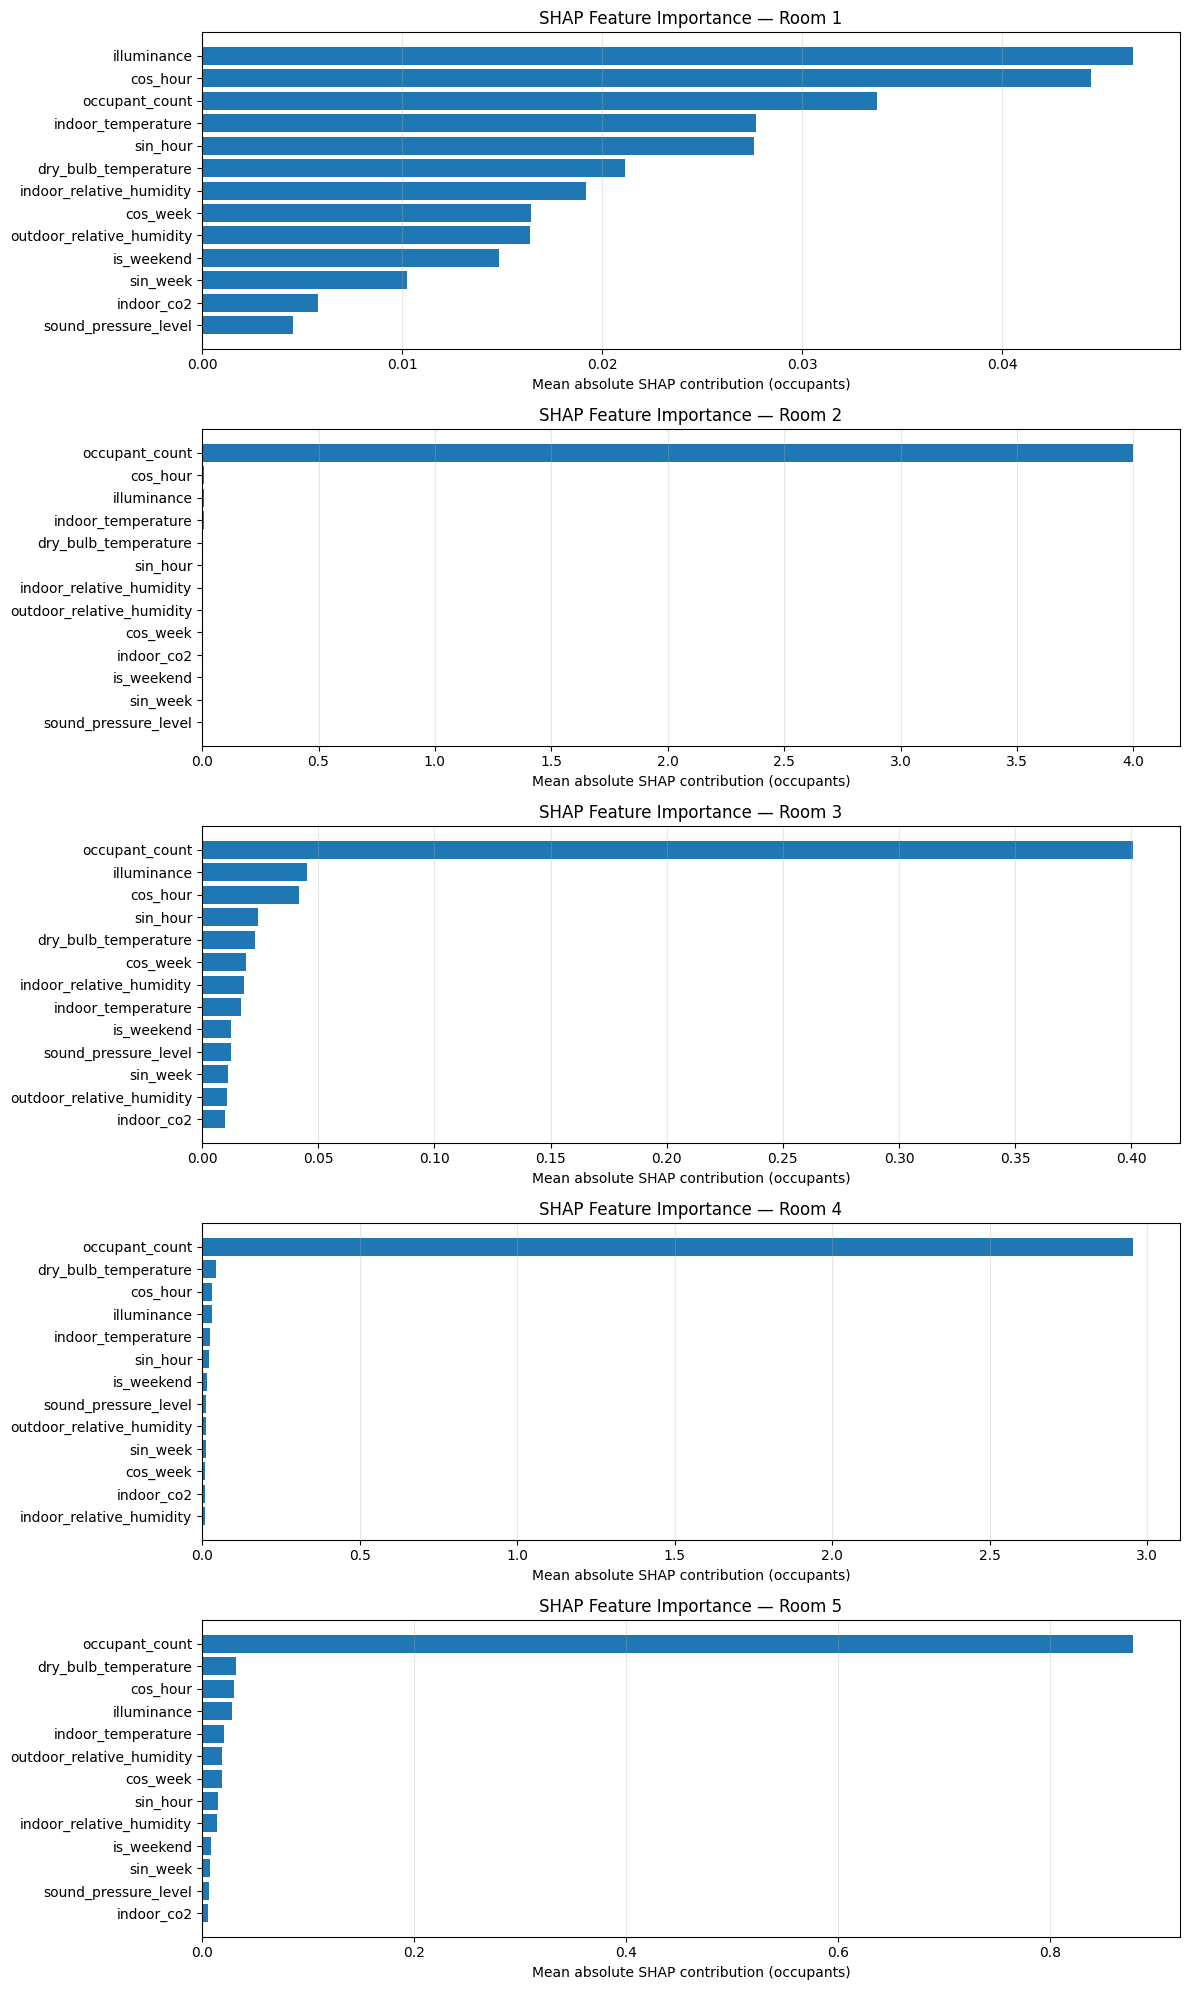

In [52]:

# ============================================================
# STEP 4: GLOBAL SHAP FEATURE IMPORTANCE
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# importance_df was created in Step 3
print("Global feature importance:")
display(importance_df.round(4))

fig, axes = plt.subplots(
    len(ROOMS), 1,
    figsize=(12, 4 * len(ROOMS))
)

axes = np.atleast_1d(axes)

for i, room in enumerate(ROOMS):
    values = importance_df[room].sort_values()

    axes[i].barh(values.index, values.values)
    axes[i].set_title(f"SHAP Feature Importance — {room}")
    axes[i].set_xlabel(
        "Mean absolute SHAP contribution (occupants)"
    )
    axes[i].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(XAI_DIR, "global_feature_importance.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()


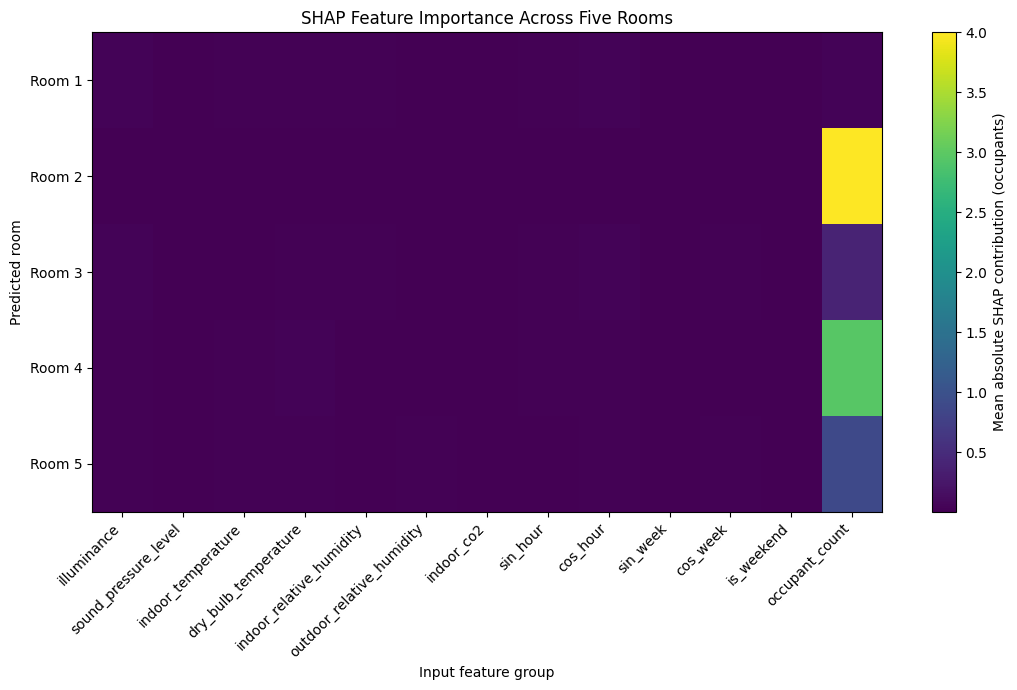

In [53]:

# ============================================================
# STEP 5: CROSS-ROOM FEATURE IMPORTANCE COMPARISON
# ============================================================

plt.figure(figsize=(11, 7))

plt.imshow(
    importance_df.T.values,
    aspect="auto"
)

plt.xticks(
    range(len(INPUT_FEATURES)),
    INPUT_FEATURES,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(ROOMS)),
    ROOMS
)

plt.xlabel("Input feature group")
plt.ylabel("Predicted room")
plt.title("SHAP Feature Importance Across Five Rooms")

plt.colorbar(
    label="Mean absolute SHAP contribution (occupants)"
)

plt.tight_layout()

plt.savefig(
    os.path.join(XAI_DIR, "feature_importance_heatmap.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


,Feature,SHAP contribution
12,occupant_count,0.1168
8,cos_hour,0.0228
3,dry_bulb_temperature,-0.0192
1,sound_pressure_level,-0.0165
7,sin_hour,0.0108
0,illuminance,0.0094
4,indoor_relative_humidity,-0.0059
6,indoor_co2,0.0057
2,indoor_temperature,0.0056
5,outdoor_relative_humidity,0.0032


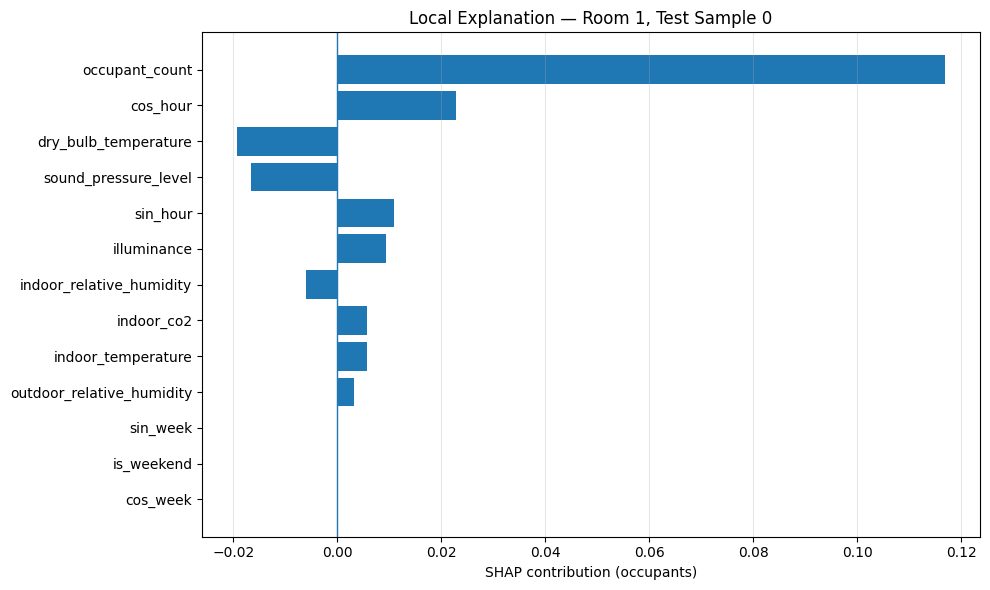

In [54]:

# ============================================================
# STEP 6: LOCAL SHAP EXPLANATION
# ============================================================

TARGET_ROOM = ROOMS[0]  # Start with Room 1
SAMPLE_INDEX = 0

local_values = shap_by_room[TARGET_ROOM][SAMPLE_INDEX]

local_df = pd.DataFrame({
    "Feature": INPUT_FEATURES,
    "SHAP contribution": local_values
})

local_df = local_df.sort_values(
    "SHAP contribution",
    key=lambda x: x.abs(),
    ascending=True
)

display(
    local_df.sort_values(
        "SHAP contribution",
        key=lambda x: x.abs(),
        ascending=False
    ).round(4)
)

plt.figure(figsize=(10, 6))

plt.barh(
    local_df["Feature"],
    local_df["SHAP contribution"]
)

plt.axvline(0, linewidth=1)
plt.xlabel("SHAP contribution (occupants)")
plt.title(
    f"Local Explanation — {TARGET_ROOM}, "
    f"Test Sample {SAMPLE_INDEX}"
)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        XAI_DIR,
        f"local_explanation_{TARGET_ROOM.replace(' ', '_')}.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


,Test sample,Actual occupancy,Predicted occupancy,Absolute error
1,1,0.0,0.317,0.317
0,0,0.0,0.154,0.154
2,2,0.0,0.106,0.106
4,4,0.0,0.079,0.079
9,9,0.0,0.028,0.028
7,7,0.0,-0.022,0.022
8,8,0.0,-0.020,0.020
3,3,0.0,0.018,0.018
5,5,0.0,0.007,0.007
6,6,0.0,0.007,0.007


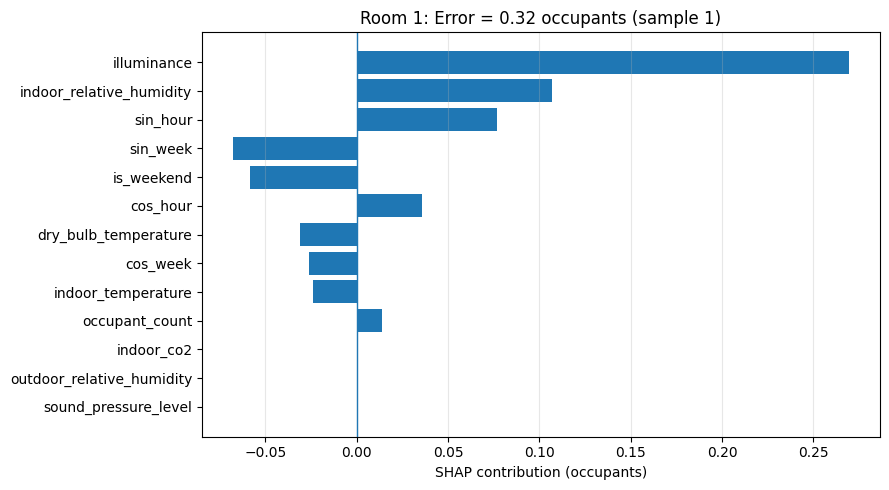

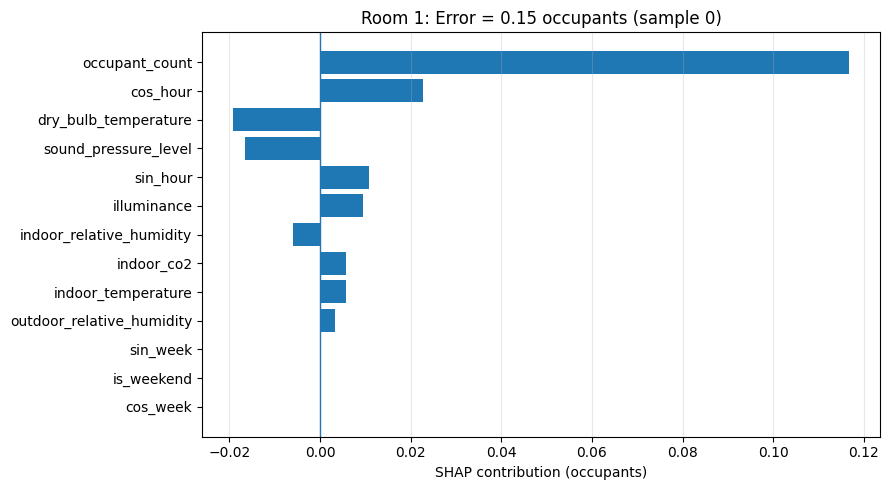

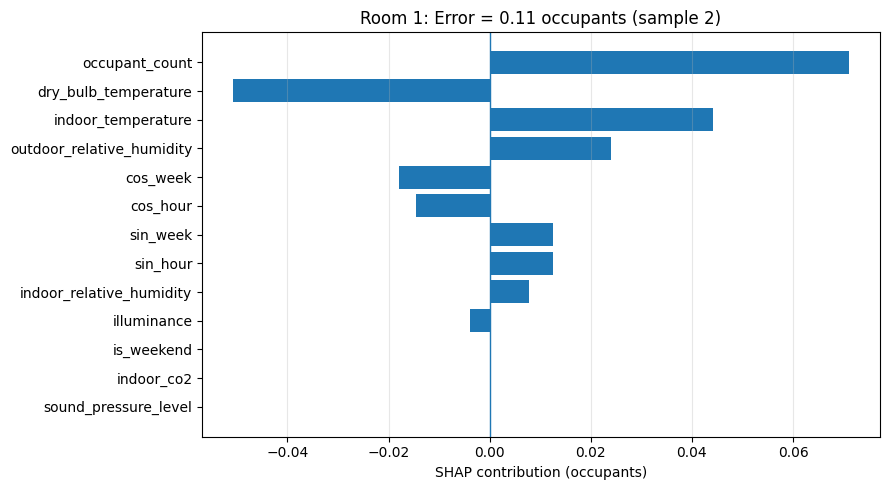

In [55]:

# ============================================================
# STEP 7: EXPLAIN HIGH-ERROR TEST SAMPLES
# ============================================================

TARGET_ROOM = "Room 1"

room_idx = ROOMS.index(TARGET_ROOM)

# Predictions for the same test samples explained in Step 3.
pred_scaled = xai_model.predict(
    X_EXPLAIN,
    verbose=0
)[:, room_idx]

scaler = target_scalers[TARGET_ROOM]

pred_actual = (
    pred_scaled * scaler.scale_[0] + scaler.mean_[0]
)

# Use the same selected test indices as X_EXPLAIN.
actual_scaled = Y_test[explain_idx, room_idx]

actual = (
    actual_scaled * scaler.scale_[0] + scaler.mean_[0]
)

errors = np.abs(actual - pred_actual)

error_df = pd.DataFrame({
    "Test sample": np.arange(len(X_EXPLAIN)),
    "Actual occupancy": actual,
    "Predicted occupancy": pred_actual,
    "Absolute error": errors
})

error_df = error_df.sort_values(
    "Absolute error",
    ascending=False
)

display(error_df.round(3))

# Plot the three largest-error explanations
top_indices = error_df["Test sample"].head(3).astype(int).tolist()

for sample_idx in top_indices:

    vals = shap_by_room[TARGET_ROOM][sample_idx]

    order = np.argsort(np.abs(vals))

    plt.figure(figsize=(9, 5))
    plt.barh(
        np.array(INPUT_FEATURES)[order],
        vals[order]
    )
    plt.axvline(0, linewidth=1)

    plt.title(
        f"{TARGET_ROOM}: Error = {errors[sample_idx]:.2f} occupants "
        f"(sample {sample_idx})"
    )
    plt.xlabel("SHAP contribution (occupants)")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


In [56]:

# ============================================================
# STEP 8: EXPORT XAI RESULTS
# ============================================================

importance_df.to_csv(
    os.path.join(XAI_DIR, "global_feature_importance.csv")
)

for room in ROOMS:
    room_df = pd.DataFrame({
        "Feature": INPUT_FEATURES,
        "Mean absolute SHAP": np.mean(
            np.abs(shap_by_room[room]), axis=0
        )
    }).sort_values(
        "Mean absolute SHAP",
        ascending=False
    )

    room_df.to_csv(
        os.path.join(
            XAI_DIR,
            f"{room.replace(' ', '_')}_feature_importance.csv"
        ),
        index=False
    )

print("XAI results saved in:", XAI_DIR)
print("Files:", sorted(os.listdir(XAI_DIR)))


XAI results saved in: /content/joint_lstm_gnn_results/xai_shap
Files: ['Room_1_feature_importance.csv', 'Room_2_feature_importance.csv', 'Room_3_feature_importance.csv', 'Room_4_feature_importance.csv', 'Room_5_feature_importance.csv', 'feature_importance_heatmap.png', 'global_feature_importance.csv', 'global_feature_importance.png', 'grouped_shap_values.npz', 'local_explanation_Room_1.png']
